# Distribution of Power Plants in Indonesia - Yana Wicaksana

---
## 1. Analysis Background

Electricity is one of the basic needs for development. With electricity demand frequently in the news, this study looks at how power plants are distributed across Indonesia and how that compares with electricity demand in each province.

**Study Objectives**
1. Prepare point data of power plants.
2. Convert coordinates into Point geometries and make sure the geometries are valid.
3. Manage the CRS so that province areas are calculated accurately (km²).
4. Link power plants to provinces (spatial join) to calculate the count, density, capacity, and share of renewable energy per province.
5. Combine electricity consumption data to see whether the distribution of power plants matches electricity demand in each province.
6. Produce ready-to-use spatial data (CSV, GeoJSON, GeoPackage) for further analysis.

**Data used**
1. Power plants: Source: OpenStreetMap
2. Province boundaries: Source: geoBoundaries (gbOpen, IDN ADM1)
3. Electricity consumption: Source: BPS (Statistics Indonesia) 2024

---
## 2. Summary of the Process

Workflow: **Data Preparation → Exploration → Cleaning & Transformation → Geometry Processing → CRS Management → Geometry Operations → Data Distribution → Energy Mix → Electricity Consumption → Correlation → Raster Analysis → Spatial Visualization → Export → Evaluation**

### 2.1 Library setup

In [1]:
import os, re, time, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

pd.set_option("display.max_columns", 30)
os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)
# Chart style: quiet axes, hairline grid, one consistent palette for every chart
from matplotlib.ticker import FuncFormatter
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
COLORS_CAT = {"Renewable": AQUA, "Fossil": ORANGE, "Unknown": NEUTRAL}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 10, "text.color": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.titlepad": 10, "axes.labelsize": 9.5, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.labelsize": 9, "ytick.labelsize": 9, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "xtick.minor.size": 0, "ytick.minor.size": 0,
    "legend.frameon": False, "legend.fontsize": 9,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
})

def chart_title(ax, title, subtitle=None):
    """Left-aligned bold title with an optional grey subtitle underneath."""
    ax.set_title(title, pad=24 if subtitle else 10)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", va="bottom", ha="left", fontsize=9.5, color=INK2)

from matplotlib.colors import BoundaryNorm

def classed(cmap_name, bins):
    """Discrete colour classes, so one extreme value (e.g. Jakarta) doesn't wash out the map."""
    cmap = plt.get_cmap(cmap_name, len(bins) - 1)
    return {"cmap": cmap, "norm": BoundaryNorm(bins, cmap.N)}

def tidy_colorbar(fig):
    """Remove the heavy outline from the colourbars geopandas adds."""
    for a in fig.axes:
        if a.get_label() == "<colorbar>":
            for spine in a.spines.values():
                spine.set_visible(False)
            a.tick_params(length=0, labelsize=8.5)

def display_name(name):
    """Title case for labels, keeping the DKI abbreviation."""
    return name.title().replace("Dki ", "DKI ")

def fmt_num(x, _=None):
    """Clean tick labels for log axes: 0.01, 0.1, 1, 10, 1,000."""
    return f"{x:,.0f}" if x >= 1 else f"{x:g}"

print("pandas", pd.__version__, "| numpy", np.__version__, "| geopandas", gpd.__version__)

pandas 3.1.1 | numpy 2.5.4 | geopandas 1.2.0


### 2.2 Source Data

a) Power plant data (OpenStreetMap, CSV format).

In [2]:
RAW_CSV = "data/Data Pembangkit Listrik.csv"
print("Data file:", RAW_CSV, "|", round(os.path.getsize(RAW_CSV) / 1024, 1), "KB")

Data file: data/Data Pembangkit Listrik.csv | 50.3 KB


b) Province boundaries from geoBoundaries.

In [3]:
PROV_FILE = "data/provinsi_idn.geojson"

if not os.path.exists(PROV_FILE):
    meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM1/", timeout=120)
    meta.raise_for_status()
    meta = meta.json()
    geojson_url = meta.get("simplifiedGeometryGeoJSON") or meta.get("gjDownloadURL")
    print("Downloading:", geojson_url)
    resp = requests.get(geojson_url, timeout=300)
    resp.raise_for_status()
    with open(PROV_FILE, "wb") as f:
        f.write(resp.content)

provinces = gpd.read_file(PROV_FILE)
provinces = provinces.rename(columns={"shapeName": "province"})[["province", "geometry"]]
print(provinces.shape, "| CRS:", provinces.crs)
provinces.head()

(34, 2) | CRS: EPSG:4326


,province,geometry
0,Bali,"MULTIPOLYGON (((114.5197 -8.1, 114.52752 -8.09..."
1,West Nusa Tenggara,"MULTIPOLYGON (((119.23765 -8.66347, 119.23498 ..."
2,Banten,"MULTIPOLYGON (((105.53122 -7.03135, 105.53102 ..."
3,Central Java,"MULTIPOLYGON (((108.88484 -6.80937, 108.88532 ..."
4,West Java,"POLYGON ((106.39563 -6.98024, 106.4008 -6.9773..."


### 2.3 Data Exploration
Check the structure, attribute types, and number of records. The CSV column names are renamed to English first.

In [4]:
df = pd.read_csv(RAW_CSV).rename(columns={
    "nama": "name",
    "sumber_raw": "source_raw",
    "metode": "method",
    "kapasitas_raw": "capacity_raw",
})
print("Data size:", df.shape)
df.head()

Data size: (638, 9)


,osm_id,osm_type,name,source_raw,method,capacity_raw,operator,latitude,longitude
0,node/7658115634,node,PLN ranting Pagar Alam,NaN,NaN,NaN,NaN,-4.035826,103.260850
1,node/14105765137,node,PLTA Renun,hydro,NaN,NaN,NaN,2.786535,98.540614
2,way/29367652,way,PLTGU Muara Karang,gas,combustion,1908 MW,PT Pembangkitan Jawa Bali,-6.110084,106.784575
3,way/92905337,way,PLTU Cilacap,coal,combustion,2121 MW,PT Sumber Segara Primadaya,-7.684896,109.093120
4,way/101264872,way,PLTP Lahendong I & II,geothermal,NaN,40 MW,NaN,1.254554,124.822146


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 638 entries, 0 to 637
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   osm_id        638 non-null    str    
 1   osm_type      638 non-null    str    
 2   name          524 non-null    str    
 3   source_raw    552 non-null    str    
 4   method        354 non-null    str    
 5   capacity_raw  502 non-null    str    
 6   operator      211 non-null    str    
 7   latitude      638 non-null    float64
 8   longitude     638 non-null    float64
dtypes: float64(2), str(7)
memory usage: 45.0 KB


In [6]:
display(df[["latitude", "longitude"]].describe())
display(df["osm_type"].value_counts().rename("count").to_frame())

,latitude,longitude
count,638.000000,638.000000
mean,-3.750003,113.120545
std,4.012017,9.299973
min,-10.883984,95.075543
25%,-7.139389,106.612312
50%,-4.821886,112.315066
75%,0.027305,120.019203
max,5.874998,140.791304


,count
osm_type,
way,613
relation,23
node,2


### 2.4 Data Cleaning & Transformation

In [7]:
# Check missing values
mv = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
}).sort_values("missing_pct", ascending=False)
mv

,missing_count,missing_pct
operator,427,66.9
method,284,44.5
capacity_raw,136,21.3
name,114,17.9
source_raw,86,13.5
osm_id,0,0.0
osm_type,0,0.0
latitude,0,0.0
longitude,0,0.0


In [8]:
# Check duplicates
# OSM ids are only unique per element type (node / way / relation), so the key is osm_type + osm_id
dup_id = df.duplicated(subset=["osm_type", "osm_id"]).sum()
dup_name_coord = df.duplicated(subset=["name", "latitude", "longitude"]).sum()
print("Duplicate osm_type + osm_id    :", dup_id)
print("Duplicate name + coordinates   :", dup_name_coord)

# Coordinates outside Indonesia's bounding box (rough estimate)
outside_bbox = (~df["longitude"].between(94, 142) | ~df["latitude"].between(-11.5, 6.5)).sum()
print("Coordinates outside Indonesia bbox:", outside_bbox)

Duplicate osm_type + osm_id    : 0
Duplicate name + coordinates   : 0
Coordinates outside Indonesia bbox: 0


In [9]:
# Check spelling of energy sources
df["source_raw"].value_counts(dropna=False).head(25)

source_raw
solar             137
coal              122
hydro              95
NaN                86
gas                81
geothermal         45
diesel             42
wind               11
oil                 5
waste               5
diesel;gas          3
biomass             2
coal;oil            1
waste_heat;gas      1
biogas              1
oil;gas             1
Name: count, dtype: int64

In [10]:
# Inconsistent capacity format (different units, free text)
df["capacity_raw"].dropna().sample(min(20, df["capacity_raw"].notna().sum()), random_state=1).tolist()

['15.6 MW',
 '70 MW',
 '200 MW',
 '21.6 MW',
 '224.4 kW',
 '200 MW',
 '110 MW',
 '10.2 MW',
 'yes',
 '114 MW',
 '134.4 kW',
 'yes',
 '130 MW',
 '224 MW',
 'yes',
 'yes',
 '147.2 kW',
 'yes',
 '250 MW',
 '1.6 MW']

In [11]:
df_clean = df.copy()
n_initial = len(df_clean)

# 1) Remove duplicates & rows without coordinates
df_clean = df_clean.drop_duplicates(subset=["osm_type", "osm_id"])
df_clean = df_clean.dropna(subset=["latitude", "longitude"])

# 2) Remove coordinates outside Indonesia's bounding box
df_clean = df_clean[df_clean["longitude"].between(94, 142) & df_clean["latitude"].between(-11.5, 6.5)]

# 3) Tidy up names
df_clean["name"] = df_clean["name"].astype("string").str.strip().replace("", pd.NA).fillna("Unnamed")

print(f"Initial rows {n_initial:,} -> after dedup & coordinate validation {len(df_clean):,}")

Initial rows 638 -> after dedup & coordinate validation 638


In [12]:
# 4) Standardize energy sources
SOURCE_MAP = {
    "solar": "solar", "photovoltaic": "solar",
    "hydro": "hydro", "water": "hydro",
    "geothermal": "geothermal",
    "wind": "wind",
    "biomass": "bioenergy", "biofuel": "bioenergy", "biogas": "bioenergy", "waste": "bioenergy",
    "coal": "coal",
    "gas": "gas", "natural_gas": "gas",
    "oil": "oil", "diesel": "oil", "gasoline": "oil",
    "nuclear": "nuclear",
}

s = df_clean["source_raw"].astype("string").str.lower().str.strip()
df_clean["hybrid"] = s.str.contains(";", na=False)            # example: "solar;diesel"
s_main = s.str.split(";").str[0].str.strip()
df_clean["source"] = s_main.map(SOURCE_MAP)

# 5) Fill missing sources from the Indonesian abbreviation in the name (PLTU, PLTA, PLTS, ...)
#    Order matters: longer abbreviations are checked first (PLTGU before PLTG, PLTMH before PLTM).
#    PLTU = steam, PLTA/PLTM/PLTMH = hydro, PLTS = solar, PLTP = geothermal, PLTB = wind,
#    PLTD = diesel, PLTG/PLTGU/PLTMG = gas, PLTBm/PLTBg/PLTSa = biomass/biogas/waste.
NAME_PATTERNS = [
    (r"\bPLTGU\b|\bPLTMG\b", "gas"),
    (r"\bPLTMH\b|\bPLTM\b|\bPLTA\b", "hydro"),
    (r"\bPLTBM\b|\bPLTBG\b|\bPLTSA\b", "bioenergy"),
    (r"\bPLTS\b", "solar"),
    (r"\bPLTP\b", "geothermal"),
    (r"\bPLTB\b", "wind"),
    (r"\bPLTD\b", "oil"),
    (r"\bPLTG\b", "gas"),
    (r"\bPLTU\b", "coal"),   # assumption: most steam power plants (PLTU) in Indonesia burn coal
]
name_upper = df_clean["name"].str.upper()
from_name = pd.Series(pd.NA, index=df_clean.index, dtype="string")
for pattern, label in NAME_PATTERNS:
    match = name_upper.str.contains(pattern, regex=True, na=False) & from_name.isna()
    from_name[match] = label

missing = df_clean["source"].isna()
df_clean["source_from_name"] = missing & from_name.notna()
df_clean.loc[missing, "source"] = from_name[missing]
df_clean["source"] = df_clean["source"].fillna("unknown")

print("Sources filled from name:", int(df_clean["source_from_name"].sum()))
df_clean["source"].value_counts()

Sources filled from name: 13


source
solar         138
coal          126
hydro          97
gas            81
unknown        74
oil            58
geothermal     45
wind           11
bioenergy       8
Name: count, dtype: int64

In [13]:
# 6) Convert capacity text -> number (MW)
FACTOR = {"gw": 1000.0, "mw": 1.0, "kw": 0.001, "w": 1e-6}

def to_number(text):
    if re.fullmatch(r"\d{1,3}(\.\d{3}){2,}", text):   # 1.000.000 (dot as thousands separator)
        return float(text.replace(".", ""))
    # Note: a single group such as "1.200" stays a decimal (1.2), the OSM convention
    if "," in text and "." in text:            # 1,200.5 -> 1200.5
        text = text.replace(",", "")
    elif "," in text:
        # 1,200 (thousands) vs 1,5 (Indonesian-style decimal)
        text = text.replace(",", "") if re.fullmatch(r"\d{1,3}(,\d{3})+", text) else text.replace(",", ".")
    return float(text)

# Accepted units: GW/MW/kW/W, optionally followed by p (peak), e/el (electric), ac/dc.
# Anything else (e.g. "kVA", "MWh") is not a power capacity in MW and becomes NaN.
UNIT = re.compile(r"^(gw|mw|kw|w)(p|e|el|ac|dc)?$")

def unit_factor(letters):
    if letters == "":
        return FACTOR["mw"]                     # no unit: assumed MW
    m = UNIT.match(letters)
    return FACTOR[m.group(1)] if m else None

def parse_capacity_mw(value):
    if pd.isna(value):
        return np.nan
    t = str(value).lower().replace(" ", "")
    try:
        m = re.match(r"^(\d+)x([\d.,]+)([a-z]*)", t)          # format "2x50MW"
        if m:
            f = unit_factor(m.group(3))
            return np.nan if f is None else int(m.group(1)) * to_number(m.group(2)) * f
        m = re.match(r"^([\d.,]+)([a-z]*)", t)
        if m:
            f = unit_factor(m.group(2))
            return np.nan if f is None else to_number(m.group(1)) * f
    except ValueError:
        pass
    return np.nan                                                       # example: "yes"

df_clean["capacity_mw"] = df_clean["capacity_raw"].apply(parse_capacity_mw)

# Unrealistic values (<= 0 or > 6,000 MW for a single plant) are treated as input errors
unrealistic = (df_clean["capacity_mw"] <= 0) | (df_clean["capacity_mw"] > 6000)
print("Unrealistic capacities removed:", int(unrealistic.sum()))
df_clean.loc[unrealistic, "capacity_mw"] = np.nan

print("Capacity filled:", int(df_clean["capacity_mw"].notna().sum()), "of", len(df_clean))
df_clean["capacity_mw"].describe()

Unrealistic capacities removed: 0
Capacity filled: 413 of 638


count     413.000000
mean      180.887075
std       509.670383
min         0.036000
25%         6.000000
50%        35.720000
75%       120.000000
max      4710.000000
Name: capacity_mw, dtype: float64

In [14]:
# 7) Derived attributes with NumPy
RENEWABLE = ["solar", "hydro", "geothermal", "wind", "bioenergy"]
FOSSIL = ["coal", "gas", "oil"]

df_clean["category"] = np.select(
    [df_clean["source"].isin(RENEWABLE), df_clean["source"].isin(FOSSIL)],
    ["Renewable", "Fossil"],
    default="Unknown",
)

df_clean["capacity_class"] = pd.cut(
    df_clean["capacity_mw"],
    bins=[0, 10, 100, 1000, np.inf],
    labels=["Small (<10 MW)", "Medium (10-100 MW)", "Large (100-1000 MW)", "Very large (>1000 MW)"],
)
df_clean["log10_capacity"] = np.log10(df_clean["capacity_mw"])   # useful for map symbol sizes

df_clean = df_clean.reset_index(drop=True)
df_clean[["name", "source", "category", "capacity_mw", "capacity_class"]].head(10)

,name,source,category,capacity_mw,capacity_class
0,PLN ranting Pagar Alam,unknown,Unknown,NaN,NaN
1,PLTA Renun,hydro,Renewable,NaN,NaN
2,PLTGU Muara Karang,gas,Fossil,1908.0,Very large (>1000 MW)
3,PLTU Cilacap,coal,Fossil,2121.0,Very large (>1000 MW)
4,PLTP Lahendong I & II,geothermal,Renewable,40.0,Medium (10-100 MW)
5,PLTU Tello,coal,Fossil,120.0,Large (100-1000 MW)
6,Unnamed,unknown,Unknown,NaN,NaN
7,Pembangkit Listrik Tenaga Uap Perak,unknown,Unknown,NaN,NaN
8,PLTD Tenau,oil,Fossil,6.4,Small (<10 MW)
9,PLTD Bau-bau,oil,Fossil,NaN,NaN


In [15]:
# Data quality summary: before vs after
quality_summary = pd.DataFrame({
    "Before": [len(df), df["source_raw"].isna().sum(), df["source_raw"].nunique(), df["capacity_raw"].notna().sum()],
    "After": [len(df_clean), (df_clean["source"] == "unknown").sum(),
              df_clean["source"].nunique(), df_clean["capacity_mw"].notna().sum()],
}, index=["Number of rows", "Missing energy source", "Distinct source labels", "Capacity filled (text -> MW number)"])
quality_summary

,Before,After
Number of rows,638,638
Missing energy source,86,74
Distinct source labels,15,9
Capacity filled (text -> MW number),502,413


### 2.5 Creating Point geometry (GeoPandas)
The `longitude` (x) and `latitude` (y) columns are converted into Point geometries with CRS **EPSG:4326** (WGS 84, degrees), matching the original coordinate system of the OSM data.

In [16]:
plants = gpd.GeoDataFrame(
    df_clean,
    geometry=gpd.points_from_xy(df_clean["longitude"], df_clean["latitude"]),
    crs="EPSG:4326",
)
print(type(plants), "| CRS:", plants.crs)
plants[["name", "source", "geometry"]].head()

<class 'geopandas.geodataframe.GeoDataFrame'> | CRS: EPSG:4326


,name,source,geometry
0,PLN ranting Pagar Alam,unknown,POINT (103.26085 -4.03583)
1,PLTA Renun,hydro,POINT (98.54061 2.78654)
2,PLTGU Muara Karang,gas,POINT (106.78458 -6.11008)
3,PLTU Cilacap,coal,POINT (109.09312 -7.6849)
4,PLTP Lahendong I & II,geothermal,POINT (124.82215 1.25455)


### 2.6 Geometry validation
Check the presence (null/empty), type, and validity of geometries in both layers. Invalid polygons are repaired with `make_valid()`.

In [17]:
def check_geometry(gdf, layer_name):
    result = {
        "layer": layer_name,
        "feature_count": len(gdf),
        "null_geometry": int(gdf.geometry.isna().sum()),
        "empty_geometry": int(gdf.geometry.is_empty.sum()),
        "invalid": int((~gdf.geometry.is_valid).sum()),
        "geometry_types": gdf.geom_type.value_counts().to_dict(),
    }
    return result

display(pd.DataFrame([check_geometry(plants, "plants"), check_geometry(provinces, "provinces")]))

,layer,feature_count,null_geometry,empty_geometry,invalid,geometry_types
0,plants,638,0,0,0,{'Point': 638}
1,provinces,34,0,0,0,"{'MultiPolygon': 31, 'Polygon': 3}"


In [18]:
# Repair invalid polygons (if any), then check again
n_invalid = int((~provinces.geometry.is_valid).sum())
if n_invalid > 0:
    provinces["geometry"] = provinces.geometry.make_valid()
    print(f"{n_invalid} polygon(s) repaired with make_valid().")
else:
    print("All province polygons are already valid.")

provinces = provinces[~provinces.geometry.is_empty & provinces.geometry.notna()].reset_index(drop=True)
print("All valid:", bool(provinces.geometry.is_valid.all()), "| types:", list(provinces.geom_type.unique()))

All province polygons are already valid.
All valid: True | types: ['MultiPolygon', 'Polygon']


### 2.7 CRS management
Both layers are in **EPSG:4326**, whose unit is **degrees**, so they cannot be used directly to calculate area in km². Indonesia spans about 46° of longitude, or about 9 UTM zones (46–54), so a single UTM zone is not suitable for the whole country. Therefore **EPSG:6933 (WGS 84 / NSIDC EASE-Grid 2.0 Global)** is used: an **equal-area** projection in meters, which makes area comparisons between provinces fair.

In [19]:
print("Plants CRS   :", plants.crs, "| unit:", plants.crs.axis_info[0].unit_name)
print("Provinces CRS:", provinces.crs, "| unit:", provinces.crs.axis_info[0].unit_name)

AREA_CRS = "EPSG:6933"
plants_proj = plants.to_crs(AREA_CRS)
provinces_proj = provinces.to_crs(AREA_CRS)
print("After transformation:", provinces_proj.crs, "| unit:", provinces_proj.crs.axis_info[0].unit_name)

Plants CRS   : EPSG:4326 | unit: degree
Provinces CRS: EPSG:4326 | unit: degree


After transformation: EPSG:6933 | unit: metre


### 2.8 Basic geometry operations: area & centroid

In [20]:
import warnings

# Area in the projected CRS (m² -> km²)
provinces_proj["area_km2"] = (provinces_proj.area / 1e6).round(1)

# Comparison: "square degrees" in EPSG:4326 (not meaningful as km²)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    provinces_proj["area_deg2"] = provinces.area.values.round(4)

# Centroids are computed in the projected CRS, then converted back to degrees for display
centroid = provinces_proj.geometry.centroid.to_crs("EPSG:4326")
provinces_proj["centroid_lon"] = centroid.x.round(4)
provinces_proj["centroid_lat"] = centroid.y.round(4)

provinces_proj[["province", "area_deg2", "area_km2", "centroid_lon", "centroid_lat"]] \
    .sort_values("area_km2", ascending=False).head(10)

,province,area_deg2,area_km2,centroid_lon,centroid_lat
28,Papua,25.7598,315903.2,138.6606,-4.6464
5,Central Kalimantan,12.4776,153507.3,113.4169,-1.5992
7,West Kalimantan,11.9296,146818.0,111.1221,-0.0849
30,East Kalimantan,10.2823,126537.6,116.4745,0.4528
29,West Papua,7.8082,96037.7,132.9373,-2.0134
18,Riau,7.2780,89573.7,101.8232,0.5092
20,South Sumatra,6.9817,85801.6,104.1785,-3.2037
21,North Sumatra,5.8788,72301.3,99.0554,2.1890
31,North Kalimantan,5.7871,71137.7,116.2243,2.8934
8,Central Sulawesi,4.9125,60450.1,121.1927,-0.9824


In [21]:
print(f"Total area of all provinces: {provinces_proj['area_km2'].sum():,.0f} km²")

Total area of all provinces: 1,890,176 km²


### 2.9 Preparing spatial data for further analysis (spatial join)
Each power plant is assigned a province attribute. Both layers are already in the same CRS (EPSG:6933). Coastal or offshore plants that do not fall exactly inside a polygon (the boundaries are *simplified*) are matched to the nearest province within a **50 km** radius. Many small islands with solar or diesel plants are missing from geoBoundaries (also in the full-resolution file), so plants there can lie up to about 40 km from the nearest polygon. The bounding box used in cleaning also covers Singapore, Malaysia, Brunei, Timor-Leste and Papua New Guinea; this dataset was checked and contains only Indonesian locations, but with other data a large radius could assign foreign plants to Indonesian provinces. The matched plants are therefore listed so they can be checked by hand. Known case: *PLTD Pulau Panggang* (Kepulauan Seribu) is matched to Banten, although it belongs to DKI Jakarta.

In [22]:
NEAREST_MAX_M = 50_000  # small islands are missing from the boundaries; check the matched list below

joined = gpd.sjoin(plants_proj, provinces_proj[["province", "geometry"]], how="left", predicate="within")
joined = joined[~joined.index.duplicated(keep="first")]          # in case a point lies exactly on a boundary

no_province = joined["province"].isna()
print("Plants outside polygons:", int(no_province.sum()))

if no_province.any():
    nearest = gpd.sjoin_nearest(
        plants_proj.loc[no_province[no_province].index],
        provinces_proj[["province", "geometry"]],
        how="left", max_distance=NEAREST_MAX_M, distance_col="distance_m",
    )
    nearest = nearest[~nearest.index.duplicated(keep="first")]
    joined.loc[nearest.index, "province"] = nearest["province"]
    print("Matched to the nearest province:", int(nearest["province"].notna().sum()))
    # Check these by hand: far matches may be the wrong province, or another country with other input data
    display(nearest.dropna(subset=["province"])[["name", "source", "province", "distance_m"]]
            .sort_values("distance_m", ascending=False).round({"distance_m": 0}))

joined = joined.drop(columns=["index_right"], errors="ignore")
print("Still without a province (dropped):", int(joined["province"].isna().sum()))
plants_final = joined.dropna(subset=["province"]).to_crs("EPSG:4326")
plants_final[["name", "source", "category", "capacity_mw", "province"]].head()

Plants outside polygons: 24
Matched to the nearest province: 24


,name,source,province,distance_m
496,PLTS Latondu,solar,South Sulawesi,39874.0
604,Unnamed,solar,South Sulawesi,35741.0
582,Unnamed,solar,Riau Islands,31966.0
105,Gedung PLTD Pulau Panggang,oil,Banten,30949.0
495,PLTS Pasitallu Tangnga,solar,South Sulawesi,29031.0
598,Unnamed,solar,Papua,13921.0
494,Unnamed,solar,South Sulawesi,11612.0
541,Unnamed,solar,South Sulawesi,11434.0
528,PLTS Raijua,solar,East Nusa Tenggara,10027.0
471,PLTS Burungloe,solar,South Sulawesi,9882.0


Still without a province (dropped): 0


,name,source,category,capacity_mw,province
0,PLN ranting Pagar Alam,unknown,Unknown,NaN,South Sumatra
1,PLTA Renun,hydro,Renewable,NaN,North Sumatra
2,PLTGU Muara Karang,gas,Fossil,1908.0,Jakarta Special Capital Region
3,PLTU Cilacap,coal,Fossil,2121.0,Central Java
4,PLTP Lahendong I & II,geothermal,Renewable,40.0,North Sulawesi


In [23]:
# Aggregation per province
agg = plants_final.groupby("province").agg(
    plant_count=("osm_id", "count"),
    renewable_count=("category", lambda x: (x == "Renewable").sum()),
    fossil_count=("category", lambda x: (x == "Fossil").sum()),
    total_capacity_mw=("capacity_mw", "sum"),
    capacity_recorded=("capacity_mw", "count"),
).reset_index()

summary = provinces_proj[["province", "area_km2", "centroid_lon", "centroid_lat", "geometry"]].merge(agg, on="province", how="left")
numeric_cols = ["plant_count", "renewable_count", "fossil_count", "total_capacity_mw", "capacity_recorded"]
summary[numeric_cols] = summary[numeric_cols].fillna(0)

summary["density_per_10k_km2"] = (summary["plant_count"] / summary["area_km2"] * 10_000).round(2)
known = summary["renewable_count"] + summary["fossil_count"]
summary["renewable_pct"] = np.where(known > 0, (summary["renewable_count"] / known * 100).round(1), np.nan)
summary["total_capacity_mw"] = summary["total_capacity_mw"].round(1)

summary = gpd.GeoDataFrame(summary, geometry="geometry", crs=AREA_CRS).to_crs("EPSG:4326")
summary.drop(columns="geometry").sort_values("plant_count", ascending=False).head(10)

,province,area_km2,centroid_lon,centroid_lat,plant_count,renewable_count,fossil_count,total_capacity_mw,capacity_recorded,density_per_10k_km2,renewable_pct
4,West Java,37676.3,107.6223,-6.9237,83.0,55.0,21.0,13242.9,47.0,22.03,72.4
11,South Sulawesi,46162.1,120.1694,-3.7027,49.0,31.0,9.0,1804.1,18.0,10.61,77.5
25,East Java,47932.4,112.7250,-7.7200,46.0,21.0,10.0,9910.7,24.0,9.60,67.7
22,East Nusa Tenggara,46232.0,122.1792,-9.2572,44.0,31.0,11.0,294.6,33.0,9.52,73.8
30,East Kalimantan,126537.6,116.4745,0.4528,31.0,12.0,17.0,1245.1,19.0,2.45,41.4
3,Central Java,33776.3,110.2264,-7.2618,30.0,19.0,10.0,12474.7,24.0,8.88,65.5
21,North Sumatra,72301.3,99.0554,2.1890,29.0,19.0,10.0,3954.4,23.0,4.01,65.5
20,South Sumatra,85801.6,104.1785,-3.2037,21.0,3.0,16.0,3847.6,17.0,2.45,15.8
1,West Nusa Tenggara,19617.1,117.5090,-8.6057,20.0,8.0,11.0,732.6,18.0,10.20,42.1
18,Riau,89573.7,101.8232,0.5092,20.0,5.0,13.0,1104.6,11.0,2.23,27.8


### 2.10 Integrating BPS electricity consumption data
To see whether the distribution of power plants matches electricity demand, attribute data from BPS is joined to the province layer (**attribute join**).

**Source:** BPS (Statistics Indonesia), *Electricity Distributed by Province (GWh)*, year **2024 (preliminary figures)**, updated 23 January 2026 — [table link](https://www.bps.go.id/id/statistics-table/2/ODU5IzI=/listrik-yang-didistribusikan-menurut-provinsi--gwh-.html).

The BPS website is protected by bot checks, so it cannot be downloaded automatically from Colab. The values were therefore copied from the BPS table into a CSV file and read back with Pandas.

Joining challenges:
1. **Different spellings.** BPS uses capital letters and abbreviations (`KEP. RIAU`, `DI YOGYAKARTA`), while geoBoundaries may use other spellings or English names. Names must be standardized first.
2. **New provinces in Papua** (South, Central and Highland Papua, Southwest Papua) have the value `-` in BPS 2024; their consumption is still recorded under the parent province. To keep the comparison fair, the new provinces are merged into their parents (Papua and West Papua) with `dissolve`.

In [24]:
CONSUMPTION_CSV = "data/bps_electricity_distributed_2024.csv"

# Values from the BPS 2024 table (GWh). "-" in BPS is written as NaN. Province names are kept as written by BPS.
bps_data = [
    ("ACEH", 3696.14), ("SUMATERA UTARA", 13234.26), ("SUMATERA BARAT", 3955.88), ("RIAU", 8815.68),
    ("JAMBI", 2522.44), ("SUMATERA SELATAN", 6513.57), ("BENGKULU", 1230.11), ("LAMPUNG", 5991.85),
    ("KEP. BANGKA BELITUNG", 1593.50), ("KEP. RIAU", 4664.31), ("DKI JAKARTA", 38198.38),
    ("JAWA BARAT", 61637.47), ("JAWA TENGAH", 30391.43), ("DI YOGYAKARTA", 3891.18),
    ("JAWA TIMUR", 44311.84), ("BANTEN", 28396.46), ("BALI", 7301.36),
    ("NUSA TENGGARA BARAT", 2853.13), ("NUSA TENGGARA TIMUR", 1454.14),
    ("KALIMANTAN BARAT", 3559.87), ("KALIMANTAN TENGAH", 1978.76), ("KALIMANTAN SELATAN", 3972.16),
    ("KALIMANTAN TIMUR", 5948.01), ("KALIMANTAN UTARA", 266.98), ("SULAWESI UTARA", 2164.19),
    ("SULAWESI TENGAH", 1804.62), ("SULAWESI SELATAN", 8732.55), ("SULAWESI TENGGARA", 1614.48),
    ("GORONTALO", 770.93), ("SULAWESI BARAT", 570.49), ("MALUKU", 670.10), ("MALUKU UTARA", 1356.62),
    ("PAPUA BARAT", 720.64), ("PAPUA BARAT DAYA", np.nan), ("PAPUA", 1435.89),
    ("PAPUA SELATAN", np.nan), ("PAPUA TENGAH", np.nan), ("PAPUA PEGUNUNGAN", np.nan),
]
BPS_TOTAL_INDONESIA = 306219.42

pd.DataFrame(bps_data, columns=["province_bps", "consumption_gwh"]).to_csv(CONSUMPTION_CSV, index=False)
consumption = pd.read_csv(CONSUMPTION_CSV)

print(consumption.shape)
print("Provinces without a value (-):", consumption.loc[consumption["consumption_gwh"].isna(), "province_bps"].tolist())
difference = consumption["consumption_gwh"].sum() - BPS_TOTAL_INDONESIA
print(f"Total check: sum of provinces = {consumption['consumption_gwh'].sum():,.2f} GWh | "
      f"BPS INDONESIA row = {BPS_TOTAL_INDONESIA:,.2f} GWh | difference = {difference:,.2f}")
consumption.head()

(38, 2)
Provinces without a value (-): ['PAPUA BARAT DAYA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']
Total check: sum of provinces = 306,219.42 GWh | BPS INDONESIA row = 306,219.42 GWh | difference = 0.00


,province_bps,consumption_gwh
0,ACEH,3696.14
1,SUMATERA UTARA,13234.26
2,SUMATERA BARAT,3955.88
3,RIAU,8815.68
4,JAMBI,2522.44


In [25]:
# Standardize province names so BPS and geoBoundaries can be joined.
# The standard form is the Indonesian name used by BPS; English and older names are mapped to it.
ALIAS = {
    "NORTH SUMATERA": "SUMATERA UTARA", "WEST SUMATERA": "SUMATERA BARAT", "SOUTH SUMATERA": "SUMATERA SELATAN",
    "RIAU ISLANDS": "KEPULAUAN RIAU",
    "BANGKA BELITUNG": "KEPULAUAN BANGKA BELITUNG", "BANGKA BELITUNG ISLANDS": "KEPULAUAN BANGKA BELITUNG",
    "JAKARTA": "DKI JAKARTA", "JAKARTA RAYA": "DKI JAKARTA", "DAERAH KHUSUS IBUKOTA JAKARTA": "DKI JAKARTA",
    "JAKARTA SPECIAL CAPITAL REGION": "DKI JAKARTA", "SPECIAL CAPITAL REGION OF JAKARTA": "DKI JAKARTA",
    "DAERAH KHUSUS JAKARTA": "DKI JAKARTA",
    "YOGYAKARTA": "DAERAH ISTIMEWA YOGYAKARTA", "SPECIAL REGION OF YOGYAKARTA": "DAERAH ISTIMEWA YOGYAKARTA",
    "WEST JAVA": "JAWA BARAT", "CENTRAL JAVA": "JAWA TENGAH", "EAST JAVA": "JAWA TIMUR",
    "WEST NUSA TENGGARA": "NUSA TENGGARA BARAT", "EAST NUSA TENGGARA": "NUSA TENGGARA TIMUR",
    "WEST KALIMANTAN": "KALIMANTAN BARAT", "CENTRAL KALIMANTAN": "KALIMANTAN TENGAH",
    "SOUTH KALIMANTAN": "KALIMANTAN SELATAN", "EAST KALIMANTAN": "KALIMANTAN TIMUR",
    "NORTH KALIMANTAN": "KALIMANTAN UTARA",
    "NORTH SULAWESI": "SULAWESI UTARA", "CENTRAL SULAWESI": "SULAWESI TENGAH", "SOUTH SULAWESI": "SULAWESI SELATAN",
    "SOUTHEAST SULAWESI": "SULAWESI TENGGARA", "WEST SULAWESI": "SULAWESI BARAT",
    "NORTH MALUKU": "MALUKU UTARA",
    "WEST PAPUA": "PAPUA BARAT", "SOUTHWEST PAPUA": "PAPUA BARAT DAYA", "SOUTH PAPUA": "PAPUA SELATAN",
    "CENTRAL PAPUA": "PAPUA TENGAH", "HIGHLAND PAPUA": "PAPUA PEGUNUNGAN", "MOUNTAIN PAPUA": "PAPUA PEGUNUNGAN",
    "IRIAN JAYA BARAT": "PAPUA BARAT", "NANGGROE ACEH DARUSSALAM": "ACEH",
}

# Provinces created in 2022 are merged into their parent because BPS 2024 does not separate them yet
PAPUA_PARENT = {"PAPUA SELATAN": "PAPUA", "PAPUA TENGAH": "PAPUA", "PAPUA PEGUNUNGAN": "PAPUA",
                "PAPUA BARAT DAYA": "PAPUA BARAT"}

def standardize_name(name):
    s = str(name).upper().strip()
    s = re.sub(r"^PROVINSI\s+", "", s)
    s = s.replace("KEP.", "KEPULAUAN ").replace("SUMATRA", "SUMATERA")
    s = re.sub(r"^D\.?I\.?\s+(?=YOGYAKARTA)", "DAERAH ISTIMEWA ", s)
    s = re.sub(r"^D\.?K\.?I\.?\s+", "DKI ", s)
    s = re.sub(r"[^A-Z ]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return ALIAS.get(s, s)

consumption["std_name"] = consumption["province_bps"].apply(standardize_name)
summary["std_name"] = summary["province"].apply(standardize_name)

# Check names that do not match before the join
map_only = sorted(set(summary["std_name"]) - set(consumption["std_name"]))
bps_only = sorted(set(consumption["std_name"]) - set(summary["std_name"]))
print("In the map, not in BPS:", map_only or "-")
print("In BPS, not in the map:", bps_only or "-")
print("(New Papua provinces missing from the map are expected in the second list; their BPS value is '-'.)")

In the map, not in BPS: -
In BPS, not in the map: ['PAPUA BARAT DAYA', 'PAPUA PEGUNUNGAN', 'PAPUA SELATAN', 'PAPUA TENGAH']
(New Papua provinces missing from the map are expected in the second list; their BPS value is '-'.)


In [26]:
# Merge the new Papua provinces into their parents (dissolve), then attribute join with BPS
summary["group"] = summary["std_name"].replace(PAPUA_PARENT)
consumption["group"] = consumption["std_name"].replace(PAPUA_PARENT)

consumption_by_group = consumption.groupby("group", as_index=False)["consumption_gwh"].sum(min_count=1)

regions = (summary.to_crs(AREA_CRS)
           .dissolve(by="group", aggfunc={
               "province": lambda x: ", ".join(sorted(x)),
               "plant_count": "sum", "renewable_count": "sum", "fossil_count": "sum",
               "total_capacity_mw": "sum", "area_km2": "sum"})
           .reset_index()
           .rename(columns={"province": "map_provinces"}))
regions = regions.merge(consumption_by_group, on="group", how="left")

# Derived indicators (NumPy)
regions["national_consumption_share_pct"] = (regions["consumption_gwh"] / BPS_TOTAL_INDONESIA * 100).round(2)
regions["consumption_mwh_per_km2"] = (regions["consumption_gwh"] * 1000 / regions["area_km2"]).round(1)
regions = regions.to_crs("EPSG:4326")

print("Regions without consumption data:", regions.loc[regions["consumption_gwh"].isna(), "group"].tolist() or "-")
regions.drop(columns="geometry").sort_values("consumption_gwh", ascending=False).head(10)

Regions without consumption data: -


,group,map_provinces,plant_count,renewable_count,fossil_count,total_capacity_mw,area_km2,consumption_gwh,national_consumption_share_pct,consumption_mwh_per_km2
8,JAWA BARAT,West Java,83.0,55.0,21.0,13242.9,37676.3,61637.47,20.13,1636.0
10,JAWA TIMUR,East Java,46.0,21.0,10.0,9910.7,47932.4,44311.84,14.47,924.5
5,DKI JAKARTA,Jakarta Special Capital Region,6.0,0.0,4.0,4729.0,648.3,38198.38,12.47,58920.8
9,JAWA TENGAH,Central Java,30.0,19.0,10.0,12474.7,33776.3,30391.43,9.92,899.8
2,BANTEN,Banten,15.0,1.0,11.0,10370.0,9346.4,28396.46,9.27,3038.2
33,SUMATERA UTARA,North Sumatra,29.0,19.0,10.0,3954.4,72301.3,13234.26,4.32,183.0
25,RIAU,Riau,20.0,5.0,13.0,1104.6,89573.7,8815.68,2.88,98.4
27,SULAWESI SELATAN,South Sulawesi,49.0,31.0,9.0,1804.1,46162.1,8732.55,2.85,189.2
1,BALI,Bali,19.0,13.0,6.0,1184.5,5571.5,7301.36,2.38,1310.5
32,SUMATERA SELATAN,South Sumatra,21.0,3.0,16.0,3847.6,85801.6,6513.57,2.13,75.9


In [27]:
# How well does the number of power plants (OSM) match electricity consumption (BPS)?
valid = regions.dropna(subset=["consumption_gwh"])
r_pearson = np.corrcoef(valid["plant_count"], valid["consumption_gwh"])[0, 1]
r_spearman = valid["plant_count"].corr(valid["consumption_gwh"], method="spearman")
print(f"Pearson correlation  (plant count vs consumption): {r_pearson:.2f}")
print(f"Spearman correlation (rank-based)               : {r_spearman:.2f}")

# Plant count treats a 1 MW plant the same as a 1,000 MW plant, so also compare recorded capacity.
# Capacity is incomplete in OSM, so this is indicative only.
r_cap_spearman = valid["total_capacity_mw"].corr(valid["consumption_gwh"], method="spearman")
print(f"Spearman correlation (recorded MW vs consumption): {r_cap_spearman:.2f}")
print(f"(n = {len(valid)} regions: correlations on a sample this small are rough indicators)")

top5 = valid.nlargest(5, "consumption_gwh")
print(f"\nThe 5 provinces with the highest consumption account for {top5['national_consumption_share_pct'].sum():.1f}% of national consumption:")
print(top5[["group", "consumption_gwh", "national_consumption_share_pct", "plant_count"]].to_string(index=False))

Pearson correlation  (plant count vs consumption): 0.66
Spearman correlation (rank-based)               : 0.51
Spearman correlation (recorded MW vs consumption): 0.88
(n = 34 regions: correlations on a sample this small are rough indicators)

The 5 provinces with the highest consumption account for 66.3% of national consumption:
      group  consumption_gwh  national_consumption_share_pct  plant_count
 JAWA BARAT         61637.47                           20.13         83.0
 JAWA TIMUR         44311.84                           14.47         46.0
DKI JAKARTA         38198.38                           12.47          6.0
JAWA TENGAH         30391.43                            9.92         30.0
     BANTEN         28396.46                            9.27         15.0


### 2.11 Data distribution
Before mapping, look at how the main variables are distributed. This shows skewness and outliers that affect how the maps and correlations should be read:
1. **Capacity per plant**: plant sizes range from kW to GW, so a log scale is used.
2. **Capacity by energy source**: typical plant size per source.
3. **Plants by capacity class and category**: how many plants of each size are renewable vs fossil (plants without a recorded capacity are shown as their own class).
4. **Plants per province** and **electricity consumption per region**: how evenly they are spread across provinces.

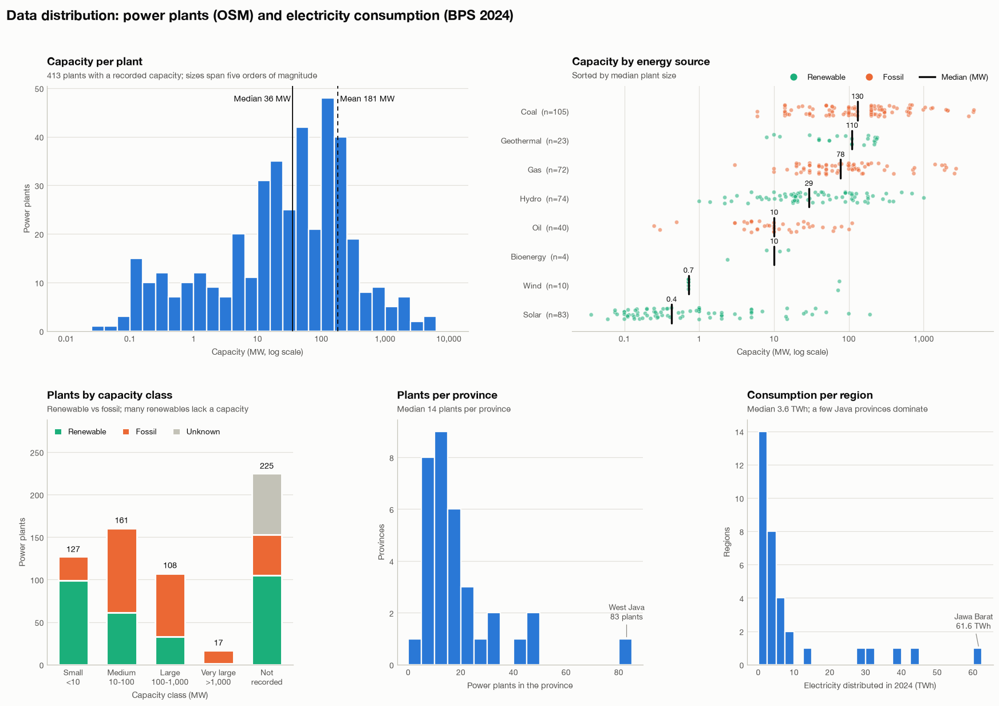

In [28]:
fig = plt.figure(figsize=(16, 11.5), layout="constrained")
fig.get_layout_engine().set(h_pad=0.25, w_pad=0.25, hspace=0.08, wspace=0.06)
gs = fig.add_gridspec(2, 6)
ax_cap, ax_src = fig.add_subplot(gs[0, :3]), fig.add_subplot(gs[0, 3:])
ax_cls, ax_prov, ax_cons = fig.add_subplot(gs[1, :2]), fig.add_subplot(gs[1, 2:4]), fig.add_subplot(gs[1, 4:])
fig.suptitle("Data distribution: power plants (OSM) and electricity consumption (BPS 2024)",
             x=0.005, ha="left", fontsize=16, fontweight="bold")

cap = plants_final["capacity_mw"].dropna()
with_cap = plants_final.dropna(subset=["capacity_mw"])

# 1) Capacity per plant: log-spaced histogram with median and mean
ax = ax_cap
bins = np.logspace(np.floor(np.log10(cap.min())), np.ceil(np.log10(cap.max())), 31)
ax.hist(cap, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(fmt_num))
top = ax.get_ylim()[1]
for value, label, ha in [(cap.median(), f"Median {cap.median():,.0f} MW ", "right"),
                         (cap.mean(), f" Mean {cap.mean():,.0f} MW", "left")]:
    ax.axvline(value, color=INK, linewidth=1.2, linestyle="-" if ha == "right" else (0, (4, 3)))
    ax.text(value, top * 0.97, label, ha=ha, va="top", fontsize=9.5, color=INK)
ax.set_xlabel("Capacity (MW, log scale)")
ax.set_ylabel("Power plants")
chart_title(ax, "Capacity per plant", f"{len(cap):,} plants with a recorded capacity; sizes span five orders of magnitude")

# 2) Capacity by energy source: one dot per plant, black tick = median
ax = ax_src
rng = np.random.default_rng(0)
order = (with_cap[with_cap["source"] != "unknown"]
         .groupby("source")["capacity_mw"].median().sort_values().index)
for i, s in enumerate(order):
    sub = with_cap[with_cap["source"] == s]
    ax.scatter(sub["capacity_mw"], i + rng.uniform(-0.2, 0.2, len(sub)), s=22, alpha=0.55,
               color=sub["category"].map(COLORS_CAT), edgecolors=SURFACE, linewidths=0.6, zorder=2)
    med = sub["capacity_mw"].median()
    ax.plot([med, med], [i - 0.32, i + 0.32], color=INK, linewidth=2.2, solid_capstyle="round", zorder=3)
    ax.text(med, i + 0.36, f"{med:,.1f}" if med < 10 else f"{med:,.0f}", ha="center", va="bottom",
            fontsize=8.5, color=INK)
ax.set_yticks(range(len(order)),
              [f"{s.capitalize()}  (n={(with_cap['source'] == s).sum()})" for s in order])
ax.set_ylim(-0.6, len(order) - 0.15)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(fmt_num))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Capacity (MW, log scale)")
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=COLORS_CAT[c], label=c)
                   for c in ["Renewable", "Fossil"]] +
                  [plt.Line2D([], [], color=INK, linewidth=2.2, label="Median (MW)")],
          loc="lower right", ncol=3, bbox_to_anchor=(1, 1.0), borderaxespad=0.2)
chart_title(ax, "Capacity by energy source", "Sorted by median plant size")

# 3) Capacity class x category: stacked columns, totals on top
ax = ax_cls
class_counts = (plants_final.assign(capacity_class=plants_final["capacity_class"]
                                    .cat.add_categories("Not recorded").fillna("Not recorded"))
                .groupby(["capacity_class", "category"], observed=False).size().unstack(fill_value=0)
                [["Renewable", "Fossil", "Unknown"]])
x = np.arange(len(class_counts))
bottom = np.zeros(len(class_counts))
for cat in class_counts.columns:
    ax.bar(x, class_counts[cat], bottom=bottom, width=0.62, color=COLORS_CAT[cat],
           edgecolor=SURFACE, linewidth=2, label=cat)
    bottom += class_counts[cat].values
for xi, total in zip(x, bottom):
    ax.text(xi, total + bottom.max() * 0.015, f"{int(total)}", ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(x, ["Small\n<10", "Medium\n10-100", "Large\n100-1,000", "Very large\n>1,000", "Not\nrecorded"])
ax.set_xlabel("Capacity class (MW)")
ax.set_ylim(0, bottom.max() * 1.28)
ax.set_ylabel("Power plants")
ax.legend(loc="upper left", ncol=3, handlelength=1, handleheight=1)
chart_title(ax, "Plants by capacity class", "Renewable vs fossil; many renewables lack a capacity")

# 4) Plants per province
ax = ax_prov
counts = summary["plant_count"]
ax.hist(counts, bins=np.arange(0, counts.max() + 6, 5), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
top_prov = summary.loc[counts.idxmax()]
ax.annotate(f"{top_prov['province']}\n{int(top_prov['plant_count'])} plants",
            xy=(top_prov["plant_count"], 1), xytext=(0, 22), textcoords="offset points",
            ha="center", fontsize=9, color=INK2, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_xlabel("Power plants in the province")
ax.set_ylabel("Provinces")
ax.yaxis.get_major_locator().set_params(integer=True)
chart_title(ax, "Plants per province", f"Median {counts.median():.0f} plants per province")

# 5) Consumption per region
ax = ax_cons
twh = valid["consumption_gwh"] / 1000
ax.hist(twh, bins=np.arange(0, twh.max() + 3, 2.5), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
top_reg = valid.loc[valid["consumption_gwh"].idxmax()]
ax.annotate(f"{display_name(top_reg['group'])}\n{top_reg['consumption_gwh'] / 1000:.1f} TWh",
            xy=(top_reg["consumption_gwh"] / 1000, 1), xytext=(-6, 22), textcoords="offset points",
            ha="center", fontsize=9, color=INK2, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_xlabel("Electricity distributed in 2024 (TWh)")
ax.set_ylabel("Regions")
ax.yaxis.get_major_locator().set_params(integer=True)
chart_title(ax, "Consumption per region", f"Median {twh.median():.1f} TWh; a few Java provinces dominate")

plt.show()

In [29]:
# Numeric summary of the distributions
dist = {
    "Capacity per plant (MW)": plants_final["capacity_mw"],
    "Plants per province": summary["plant_count"],
    "Density per 10,000 km²": summary["density_per_10k_km2"],
    "Consumption per region (GWh)": valid["consumption_gwh"],
}
dist_summary = pd.DataFrame({
    name: {"n": s.notna().sum(), "min": s.min(), "median": s.median(), "mean": s.mean(),
           "max": s.max(), "skewness": s.skew()}
    for name, s in dist.items()
}).T.round(2)
display(dist_summary)

top10_share = cap.nlargest(int(np.ceil(len(cap) * 0.10))).sum() / cap.sum() * 100
print(f"The largest 10% of plants (by recorded capacity) hold {top10_share:.1f}% of all recorded MW.")
print("Capacity by source (MW):")
display(with_cap.groupby("source")["capacity_mw"]
        .agg(["count", "median", "mean", "max", "sum"]).round(1).sort_values("sum", ascending=False))

,n,min,median,mean,max,skewness
Capacity per plant (MW),413.0,0.04,35.72,180.89,4710.00,5.83
Plants per province,34.0,0.00,14.00,18.76,83.00,2.29
"Density per 10,000 km²",34.0,0.00,3.84,9.07,92.55,4.27
Consumption per region (GWh),34.0,266.98,3628.00,9006.45,61637.47,2.42


The largest 10% of plants (by recorded capacity) hold 69.8% of all recorded MW.
Capacity by source (MW):


,count,median,mean,max,sum
source,,,,,
coal,105,130.0,391.5,4710.0,41104.4
gas,72,77.5,306.2,2720.0,22043.5
hydro,74,29.2,94.8,1008.0,7015.8
geothermal,23,110.0,116.1,240.0,2670.2
oil,40,10.0,20.9,111.0,836.8
solar,83,0.4,7.0,192.0,584.9
unknown,2,130.0,130.0,200.0,260.0
wind,10,0.7,15.3,75.0,152.8
bioenergy,4,10.0,9.5,15.6,38.0


**How to read this:** all four variables are strongly right-skewed (positive skewness, mean well above the median). Recorded plant capacity spans about five orders of magnitude, from small solar units below 1 MW to coal plants of several GW, and a small share of large coal and gas plants holds most of the recorded MW (see the printed share above). Many renewable plants have no recorded capacity at all, so totals in MW under-represent them. Plant counts and consumption are also concentrated in a few provinces. This is why the maps below normalize by area, why the scatter plot uses a log scale, and why the rank-based Spearman correlation is reported alongside Pearson.

### 2.12 Energy mix: which types of energy are used
A closer look at the energy sources of Indonesia's power plants, comparing two views that tell different stories:
- **Number of plants**: how often each energy source is used.
- **Recorded capacity (MW)**: how much generating power each source provides.

Many small solar or micro-hydro plants can dominate the count while a few large coal plants dominate the capacity. The *capacity recorded* panel shows, for each source, how many plants have a capacity value in OSM, so you can judge how reliable the MW comparison is.

In [30]:
# Energy mix per source
mix = plants_final.groupby("source").agg(
    plants=("osm_id", "count"),
    with_capacity=("capacity_mw", "count"),
    total_mw=("capacity_mw", "sum"),
    median_mw=("capacity_mw", "median"),
)
mix["category"] = np.select([mix.index.isin(RENEWABLE), mix.index.isin(FOSSIL)], ["Renewable", "Fossil"], "Unknown")
mix["plants_pct"] = mix["plants"] / mix["plants"].sum() * 100
mix["mw_pct"] = mix["total_mw"] / mix["total_mw"].sum() * 100
mix["coverage_pct"] = mix["with_capacity"] / mix["plants"] * 100

# Order: known sources by recorded capacity, "unknown" last
known = mix.drop(index="unknown", errors="ignore").sort_values("total_mw", ascending=False)
mix = pd.concat([known, mix.loc[mix.index == "unknown"]])

# Largest plant per source
with_cap = plants_final.dropna(subset=["capacity_mw"])
largest = with_cap.loc[with_cap.groupby("source")["capacity_mw"].idxmax(), ["source", "name", "capacity_mw", "province"]]
largest = largest.set_index("source")

# Category shares: by plant count vs by recorded capacity
cat_order = ["Renewable", "Fossil", "Unknown"]
shares = pd.DataFrame({
    "Share of plants": plants_final["category"].value_counts(normalize=True) * 100,
    "Share of recorded capacity": plants_final.groupby("category")["capacity_mw"].sum()
                                   / plants_final["capacity_mw"].sum() * 100,
}).T.reindex(columns=cat_order).fillna(0)
shares.round(1)

category,Renewable,Fossil,Unknown
Share of plants,46.9,41.5,11.6
Share of recorded capacity,14.0,85.6,0.3


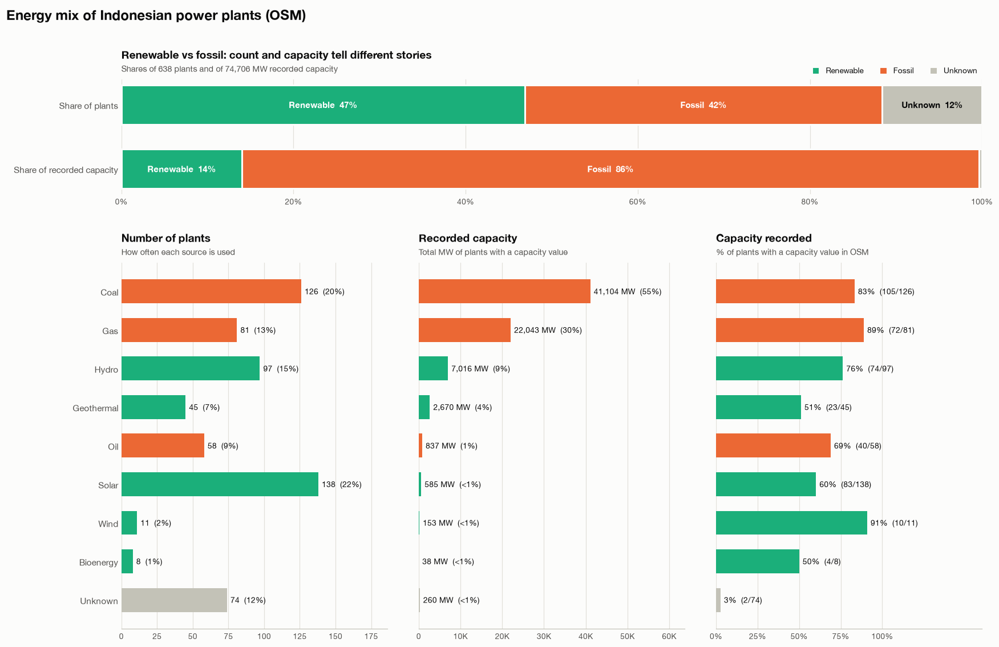

In [31]:
fig = plt.figure(figsize=(16, 10.5), layout="constrained")
fig.get_layout_engine().set(h_pad=0.2, w_pad=0.2, hspace=0.06, wspace=0.04)
gs = fig.add_gridspec(2, 3, height_ratios=[1, 3.2])
fig.suptitle("Energy mix of Indonesian power plants (OSM)", x=0.005, ha="left", fontsize=16, fontweight="bold")

# A) 100% bars: share of plants vs share of recorded capacity
ax = fig.add_subplot(gs[0, :])
for i, (label, row) in enumerate(shares.iterrows()):
    left = 0
    for cat in cat_order:
        w = row[cat]
        ax.barh(i, w, left=left, height=0.62, color=COLORS_CAT[cat], edgecolor=SURFACE, linewidth=2,
                label=cat if i == 0 else None)
        if w >= 7:
            ax.text(left + w / 2, i, f"{cat}  {w:.0f}%", ha="center", va="center", fontsize=10,
                    fontweight="bold", color="#ffffff" if cat != "Unknown" else INK)
        left += w
ax.set_yticks(range(len(shares)), shares.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=3, handlelength=1, handleheight=1, borderaxespad=0.2)
chart_title(ax, "Renewable vs fossil: count and capacity tell different stories",
            f"Shares of {len(plants_final):,} plants and of {plants_final['capacity_mw'].sum():,.0f} MW recorded capacity")

# B, C, D) Per source, same order on every panel
pct = lambda v: f"{v:.0f}%" if v >= 1 or v == 0 else "<1%"
y = np.arange(len(mix))
colors = mix["category"].map(COLORS_CAT)
labels = [s.capitalize() for s in mix.index]
panels = [
    ("plants", "Number of plants", "How often each source is used",
     lambda r: f"{int(r.plants)}  ({pct(r.plants_pct)})", 1.35),
    ("total_mw", "Recorded capacity", "Total MW of plants with a capacity value",
     lambda r: f"{r.total_mw:,.0f} MW  ({pct(r.mw_pct)})", 1.55),
    ("coverage_pct", "Capacity recorded", "% of plants with a capacity value in OSM",
     lambda r: f"{r.coverage_pct:.0f}%  ({int(r.with_capacity)}/{int(r.plants)})", 1.6),
]
first = None
for k, (col, title, subtitle, fmt, pad) in enumerate(panels):
    ax = fig.add_subplot(gs[1, k], sharey=first)
    first = first or ax
    bars = ax.barh(y, mix[col], color=colors, height=0.62)
    ax.bar_label(bars, labels=[fmt(r) for r in mix.itertuples()], padding=4, fontsize=9, color=INK)
    ax.set_xlim(0, (100 if col == "coverage_pct" else mix[col].max()) * pad)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    if col == "total_mw":
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}K" if v else "0"))
    if col == "coverage_pct":
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    if k == 0:
        ax.set_yticks(y, labels, fontsize=10)
        ax.invert_yaxis()
    else:
        ax.tick_params(axis="y", labelleft=False)
    chart_title(ax, title, subtitle)

plt.show()

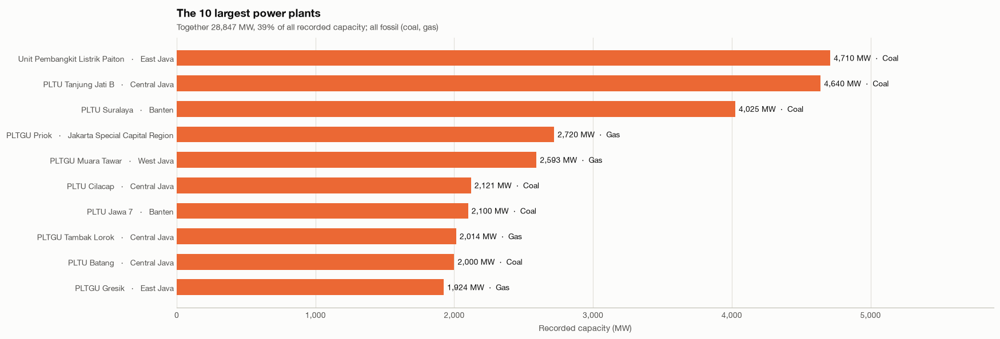

In [32]:
# The 10 largest power plants by recorded capacity
top10 = plants_final.nlargest(10, "capacity_mw").iloc[::-1]
short = lambda s, n=38: s if len(s) <= n else s[: n - 1] + "…"

fig, ax = plt.subplots(figsize=(16, 5.5))
bars = ax.barh([f"{short(r.name)}   ·   {r.province}" for r in top10.itertuples()], top10["capacity_mw"],
               color=top10["category"].map(COLORS_CAT), height=0.62)
ax.bar_label(bars, labels=[f"{r.capacity_mw:,.0f} MW  ·  {r.source.capitalize()}" for r in top10.itertuples()],
             padding=4, fontsize=9, color=INK)
ax.set_xlim(0, top10["capacity_mw"].max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Recorded capacity (MW)")
share10 = top10["capacity_mw"].sum() / plants_final["capacity_mw"].sum() * 100
cats10 = top10["category"].unique()
if len(cats10) > 1:   # legend only needed when more than one category appears
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS_CAT[c], label=c) for c in cat_order if c in cats10],
              loc="lower right", handlelength=1, handleheight=1)
note = f"; all {cats10[0].lower()} ({', '.join(sorted(top10['source'].unique()))})" if len(cats10) == 1 else ""
chart_title(ax, "The 10 largest power plants",
            f"Together {top10['capacity_mw'].sum():,.0f} MW, {share10:.0f}% of all recorded capacity{note}")
plt.tight_layout()
plt.show()

In [33]:
# Detail table per energy source
energy_table = pd.DataFrame({
    "Category": mix["category"],
    "Plants": mix["plants"].astype(int),
    "% of plants": mix["plants_pct"].round(1),
    "With capacity": mix["with_capacity"].astype(int),
    "Capacity recorded (%)": mix["coverage_pct"].round(0).astype(int),
    "Total MW": mix["total_mw"].round(0).astype(int),
    "% of MW": mix["mw_pct"].round(1),
    "Median MW": mix["median_mw"].round(1),
    "Largest plant": largest["name"].reindex(mix.index),
    "Largest MW": largest["capacity_mw"].reindex(mix.index).round(0),
    "Largest in province": largest["province"].reindex(mix.index),
})
energy_table.index = energy_table.index.str.capitalize()
energy_table.index.name = "Energy source"
display(energy_table)

ren_n, ren_mw = shares.loc["Share of plants", "Renewable"], shares.loc["Share of recorded capacity", "Renewable"]
top_src = mix["mw_pct"].idxmax()
most_used = mix.drop(index="unknown", errors="ignore")["plants"].idxmax()
print(f"Renewables are {ren_n:.0f}% of plants but only {ren_mw:.0f}% of recorded capacity.")
print(f"{top_src.capitalize()} provides the most recorded capacity: {mix.loc[top_src, 'mw_pct']:.0f}% "
      f"of MW from {mix.loc[top_src, 'plants_pct']:.0f}% of plants.")
print(f"{most_used.capitalize()} is the most common source: {mix.loc[most_used, 'plants_pct']:.0f}% of plants "
      f"but {mix.loc[most_used, 'mw_pct']:.1f}% of MW (median plant {mix.loc[most_used, 'median_mw']:.1f} MW).")

,Category,Plants,% of plants,With capacity,Capacity recorded (%),Total MW,% of MW,Median MW,Largest plant,Largest MW,Largest in province
Energy source,,,,,,,,,,,
Coal,Fossil,126,19.7,105,83,41104,55.0,130.0,Unit Pembangkit Listrik Paiton,4710.0,East Java
Gas,Fossil,81,12.7,72,89,22043,29.5,77.5,PLTGU Priok,2720.0,Jakarta Special Capital Region
Hydro,Renewable,97,15.2,74,76,7016,9.4,29.2,PLTA Cirata,1008.0,West Java
Geothermal,Renewable,45,7.1,23,51,2670,3.6,110.0,PLTP Sorik Marapi,240.0,North Sumatra
Oil,Fossil,58,9.1,40,69,837,1.1,10.0,PLTD & PLTG Trisakti,111.0,South Kalimantan
Solar,Renewable,138,21.6,83,60,585,0.8,0.4,PLTS Cirata,192.0,West Java
Wind,Renewable,11,1.7,10,91,153,0.2,0.7,PLTB Sidrap,75.0,South Sulawesi
Bioenergy,Renewable,8,1.3,4,50,38,0.1,10.0,PLTSa Bantargebang,16.0,West Java
Unknown,Unknown,74,11.6,2,3,260,0.3,130.0,Cilegon Krakatau Posco Power Plant,200.0,Banten


Renewables are 47% of plants but only 14% of recorded capacity.
Coal provides the most recorded capacity: 55% of MW from 20% of plants.
Solar is the most common source: 22% of plants but 0.8% of MW (median plant 0.4 MW).


**How to read this:** the number of plants and the installed capacity give very different pictures of Indonesia's energy mix. Renewable plants (mostly small solar and hydro units) are about half of all plants, but large coal and gas plants provide most of the recorded capacity, so the power system is still mainly fossil-based (exact shares in the printed output above). Keep the *capacity recorded* panel in mind: sources with low coverage, such as solar, may be under-represented in the MW totals. OSM is also not a complete inventory, so these shares describe the mapped plants, not official national installed capacity.

### 2.13 Electricity consumption in Indonesia (BPS 2024)
After looking at the supply side (power plants and their capacity), this section looks at the demand side: how much electricity Indonesia uses and where. The data is *Electricity Distributed by Province* from BPS (section 2.10), in GWh for 2024.

Provinces are grouped into seven island groups (Java, Sumatra, Kalimantan, Sulawesi, Bali & Nusa Tenggara, Maluku, Papua) to compare **where electricity is consumed** with **where the recorded generating capacity is located**.

Two units are used:
- **GWh (energy)**: the amount of electricity used over the year.
- **GW / MW (power)**: the generating capacity, the maximum a plant can produce at one moment.

Dividing the yearly GWh by the number of hours in 2024 (8,784, a leap year) gives the **average demand in GW**, which can be compared with capacity.

In [34]:
# Group provinces (BPS names) into island groups
ISLAND_ORDER = ["Java", "Sumatra", "Kalimantan", "Sulawesi", "Bali & Nusa Tenggara", "Maluku", "Papua"]
JAVA = {"DKI JAKARTA", "JAWA BARAT", "JAWA TENGAH", "DAERAH ISTIMEWA YOGYAKARTA", "JAWA TIMUR", "BANTEN"}
SUMATRA = {"ACEH", "RIAU", "JAMBI", "BENGKULU", "LAMPUNG", "KEPULAUAN BANGKA BELITUNG", "KEPULAUAN RIAU"}

def island_group(name):
    if name in JAVA: return "Java"
    if name in SUMATRA or name.startswith("SUMATERA"): return "Sumatra"
    if name.startswith("KALIMANTAN"): return "Kalimantan"
    if name.startswith("SULAWESI") or name == "GORONTALO": return "Sulawesi"
    if name in {"BALI", "NUSA TENGGARA BARAT", "NUSA TENGGARA TIMUR"}: return "Bali & Nusa Tenggara"
    if name.startswith("MALUKU"): return "Maluku"
    if name.startswith("PAPUA"): return "Papua"
    return None

cons = regions.drop(columns="geometry").copy()
cons["island"] = cons["group"].map(island_group)
assert cons["island"].notna().all(), cons.loc[cons["island"].isna(), "group"].tolist()

islands = (cons.groupby("island")
           .agg(consumption_gwh=("consumption_gwh", "sum"), capacity_mw=("total_capacity_mw", "sum"),
                plants=("plant_count", "sum"), provinces=("group", "count"))
           .reindex(ISLAND_ORDER))
islands["consumption_pct"] = islands["consumption_gwh"] / islands["consumption_gwh"].sum() * 100
islands["capacity_pct"] = islands["capacity_mw"] / islands["capacity_mw"].sum() * 100
islands["plants_pct"] = islands["plants"] / islands["plants"].sum() * 100

# National figures
HOURS_2024 = 366 * 24                                             # 2024 is a leap year
total_gwh = BPS_TOTAL_INDONESIA
avg_demand_gw = total_gwh / HOURS_2024                             # GWh / h = GW
recorded_gw = plants_final["capacity_mw"].sum() / 1000
java_share = islands.loc["Java", "consumption_pct"]
print(f"Electricity distributed in 2024 : {total_gwh:,.0f} GWh ({total_gwh / 1000:,.1f} TWh)")
print(f"Average demand                  : {avg_demand_gw:,.1f} GW  (= GWh / {HOURS_2024:,} hours)")
print(f"Recorded capacity (OSM)         : {recorded_gw:,.1f} GW  -> average demand is "
      f"{avg_demand_gw / recorded_gw * 100:.0f}% of recorded capacity")

Electricity distributed in 2024 : 306,219 GWh (306.2 TWh)
Average demand                  : 34.9 GW  (= GWh / 8,784 hours)
Recorded capacity (OSM)         : 74.7 GW  -> average demand is 47% of recorded capacity


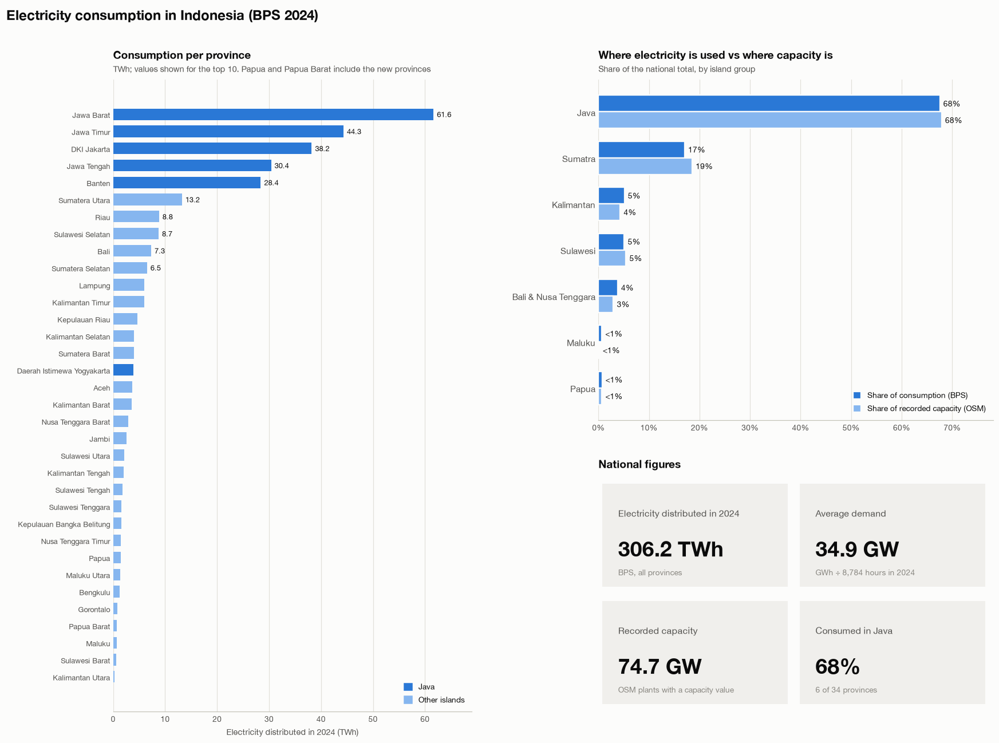

In [35]:
fig = plt.figure(figsize=(16, 12), layout="constrained")
fig.get_layout_engine().set(h_pad=0.2, w_pad=0.25, hspace=0.06, wspace=0.08)
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.1], height_ratios=[1.45, 1])
ax_reg, ax_isl, ax_kpi = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
fig.suptitle("Electricity consumption in Indonesia (BPS 2024)", x=0.005, ha="left", fontsize=16, fontweight="bold")
LIGHT_BLUE = "#86b6ef"

# A) Consumption per province, Java highlighted
ax = ax_reg
by_region = cons.sort_values("consumption_gwh")
is_java = by_region["island"] == "Java"
bars = ax.barh([display_name(g) for g in by_region["group"]], by_region["consumption_gwh"] / 1000,
               color=np.where(is_java, BLUE, LIGHT_BLUE), height=0.68)
n_label = 10
ax.bar_label(bars, labels=[f"{v / 1000:,.1f}" if i >= len(by_region) - n_label else ""
                           for i, v in enumerate(by_region["consumption_gwh"])],
             padding=4, fontsize=8.5, color=INK)
ax.set_xlim(0, by_region["consumption_gwh"].max() / 1000 * 1.12)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("Electricity distributed in 2024 (TWh)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Java"),
                   plt.Rectangle((0, 0), 1, 1, color=LIGHT_BLUE, label="Other islands")],
          loc="lower right", handlelength=1, handleheight=1)
chart_title(ax, "Consumption per province",
            f"TWh; values shown for the top {n_label}. Papua and Papua Barat include the new provinces")

# B) Share of consumption vs share of recorded capacity, per island group
ax = ax_isl
yi = np.arange(len(islands))
h = 0.36
for offset, col, color, label in [(-h / 2, "consumption_pct", BLUE, "Share of consumption (BPS)"),
                                  (h / 2, "capacity_pct", LIGHT_BLUE, "Share of recorded capacity (OSM)")]:
    b = ax.barh(yi + offset, islands[col], height=h, color=color, edgecolor=SURFACE, linewidth=1.5, label=label)
    ax.bar_label(b, labels=[f"{v:.0f}%" if v >= 1 else "<1%" for v in islands[col]], padding=4, fontsize=9, color=INK)
ax.set_yticks(yi, islands.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, islands[["consumption_pct", "capacity_pct"]].max().max() * 1.15)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower right", handlelength=1, handleheight=1)
chart_title(ax, "Where electricity is used vs where capacity is",
            "Share of the national total, by island group")

# C) Key national figures as stat tiles
ax = ax_kpi
ax.set_axis_off()
tiles = [
    (f"{total_gwh / 1000:,.1f} TWh", "Electricity distributed in 2024", "BPS, all provinces"),
    (f"{avg_demand_gw:,.1f} GW", "Average demand", f"GWh ÷ {HOURS_2024:,} hours in 2024"),
    (f"{recorded_gw:,.1f} GW", "Recorded capacity", "OSM plants with a capacity value"),
    (f"{java_share:.0f}%", "Consumed in Java", f"{int(islands.loc['Java', 'provinces'])} of {len(cons)} provinces"),
]
for k, (value, label, note) in enumerate(tiles):
    x0, y0 = (k % 2) * 0.5, 0.5 - (k // 2) * 0.5
    ax.add_patch(plt.Rectangle((x0 + 0.01, y0 + 0.03), 0.47, 0.44, transform=ax.transAxes,
                               facecolor="#f0efec", edgecolor="none"))
    ax.text(x0 + 0.05, y0 + 0.33, label, transform=ax.transAxes, fontsize=10.5, color=INK2)
    ax.text(x0 + 0.05, y0 + 0.16, value, transform=ax.transAxes, fontsize=24, fontweight="bold", color=INK)
    ax.text(x0 + 0.05, y0 + 0.08, note, transform=ax.transAxes, fontsize=9, color=MUTED)
chart_title(ax, "National figures")

plt.show()

In [36]:
# Detail table per island group
island_table = pd.DataFrame({
    "Provinces": islands["provinces"].astype(int),
    "Consumption (GWh)": islands["consumption_gwh"].round(0).astype(int),
    "% of consumption": islands["consumption_pct"].round(1),
    "Average demand (GW)": (islands["consumption_gwh"] / HOURS_2024).round(2),
    "Recorded capacity (MW)": islands["capacity_mw"].round(0).astype(int),
    "% of capacity": islands["capacity_pct"].round(1),
    "Power plants": islands["plants"].astype(int),
    "% of plants": islands["plants_pct"].round(1),
})
island_table.index.name = "Island group"
display(island_table)

top_prov = cons.loc[cons["consumption_gwh"].idxmax()]
print(f"Java uses {java_share:.0f}% of Indonesia's electricity and holds "
      f"{islands.loc['Java', 'capacity_pct']:.0f}% of the recorded capacity.")
print(f"Largest consumer: {display_name(top_prov['group'])} with {top_prov['consumption_gwh']:,.0f} GWh "
      f"({top_prov['consumption_gwh'] / total_gwh * 100:.0f}% of national).")
outside = islands.drop(index="Java")
print(f"Outside Java: {outside['consumption_pct'].sum():.0f}% of consumption, "
      f"{outside['capacity_pct'].sum():.0f}% of recorded capacity, {outside['plants_pct'].sum():.0f}% of plants.")

,Provinces,Consumption (GWh),% of consumption,Average demand (GW),Recorded capacity (MW),% of capacity,Power plants,% of plants
Island group,,,,,,,,
Java,6,206827,67.5,23.55,50727,67.9,180,28.2
Sumatra,10,52218,17.1,5.94,13858,18.5,149,23.4
Kalimantan,5,15726,5.1,1.79,3210,4.3,71,11.1
Sulawesi,6,15657,5.1,1.78,4065,5.4,110,17.2
Bali & Nusa Tenggara,3,11609,3.8,1.32,2212,3.0,83,13.0
Maluku,2,2027,0.7,0.23,126,0.2,21,3.3
Papua,2,2157,0.7,0.25,508,0.7,24,3.8


Java uses 68% of Indonesia's electricity and holds 68% of the recorded capacity.
Largest consumer: Jawa Barat with 61,637 GWh (20% of national).
Outside Java: 32% of consumption, 32% of recorded capacity, 72% of plants.


**How to read this:**
- Electricity use is heavily concentrated in **Java**, where most of the population and industry are. The island-group chart shows that recorded capacity broadly follows demand: each island group's share of capacity is close to its share of consumption (exact figures in the table above), while the *number* of plants is spread much more widely.
- **Average demand is lower than capacity, and that is expected.** A power system needs more capacity than the average demand to cover the evening peak, reserve margins, plants under maintenance, and sources that do not run all the time (solar only produces in daylight).
- **Outside Java** the share of plants is much higher than the share of consumption: many small plants (solar, diesel, micro-hydro) supply scattered islands that are not connected to a large grid.
- The comparison is indicative only: OSM capacity is incomplete, BPS measures electricity *distributed* (by PLN), not all electricity generated (for example, industrial plants that produce their own power), and electricity also flows between provinces through the grid.

### 2.14 Correlation: power plant capacity vs electricity consumption
Does a province that uses more electricity also have more generating capacity, and does this differ by type of energy?

**Important: production is approximated by capacity.** The data has no electricity *production* (GWh generated) per province, only the *recorded capacity* (MW) of OSM power plants. Capacity is the best available proxy, but it is not the same as production (plants do not run at full power all the time, and solar runs only in daylight).

What is calculated, for the 34 regions (new Papua provinces merged with their parents, as in section 2.10):
1. **Overall:** total recorded capacity and number of plants vs consumption.
2. **Per energy source:** capacity (MW) and number of plants of each source vs consumption.
3. **Capacity-to-demand ratio:** recorded capacity divided by average demand, to see which provinces have more or less capacity than they use.

**Spearman** (rank-based) correlation is the main measure because the data is strongly skewed (section 2.11). Pearson on the raw values and on log values is shown for comparison. With only 34 regions, correlations are rough indicators; the p-value shows whether a correlation could easily be chance (p < 0.05 is used as the usual threshold).

In [37]:
from scipy import stats

# Capacity and plant count per region and energy source
prov_to_group = dict(zip(summary["province"], summary["group"]))
pf = plants_final.assign(group=plants_final["province"].map(prov_to_group))
assert pf["group"].notna().all()

base = cons.set_index("group")[["consumption_gwh", "island", "total_capacity_mw", "plant_count"]]
SOURCES = [s for s in mix.index if s != "unknown"]          # ordered by national capacity
cap_by_src = (pf.pivot_table(index="group", columns="source", values="capacity_mw", aggfunc="sum", fill_value=0)
              .reindex(index=base.index, columns=SOURCES, fill_value=0))
cnt_by_src = (pf.pivot_table(index="group", columns="source", values="osm_id", aggfunc="count", fill_value=0)
              .reindex(index=base.index, columns=SOURCES, fill_value=0))

def correlate(x, y):
    """Spearman and Pearson r with p-values; NaN when x is constant."""
    if np.nanstd(x) == 0:
        return dict(spearman_r=np.nan, spearman_p=np.nan, pearson_r=np.nan, pearson_p=np.nan)
    sp, pe = stats.spearmanr(x, y), stats.pearsonr(x, y)
    return dict(spearman_r=sp.statistic, spearman_p=sp.pvalue, pearson_r=pe.statistic, pearson_p=pe.pvalue)

y = base["consumption_gwh"]
overall = pd.DataFrame({
    "Recorded capacity (MW)": correlate(base["total_capacity_mw"], y),
    "Number of plants": correlate(base["plant_count"], y),
}).T
# Pearson on log values (log1p handles regions with zero capacity)
overall["pearson_log_r"] = [stats.pearsonr(np.log1p(base[c]), np.log10(y)).statistic
                            for c in ["total_capacity_mw", "plant_count"]]
overall.insert(0, "n_regions", len(base))
print("Overall correlation with consumption (34 regions):")
display(overall.round(3))

# Per energy source
rows = []
for s in SOURCES:
    c_cap, c_cnt = correlate(cap_by_src[s], y), correlate(cnt_by_src[s], y)
    rows.append({"source": s, "category": mix.loc[s, "category"],
                 "regions_with_source": int((cnt_by_src[s] > 0).sum()),
                 "national_mw_pct": mix.loc[s, "mw_pct"],
                 "capacity_spearman_r": c_cap["spearman_r"], "capacity_p": c_cap["spearman_p"],
                 "capacity_pearson_r": c_cap["pearson_r"],
                 "count_spearman_r": c_cnt["spearman_r"], "count_p": c_cnt["spearman_p"]})
by_source_corr = pd.DataFrame(rows).set_index("source")
print("Correlation with consumption per energy source (Spearman unless noted):")
display(by_source_corr.round(3))

Overall correlation with consumption (34 regions):


,n_regions,spearman_r,spearman_p,pearson_r,pearson_p,pearson_log_r
Recorded capacity (MW),34,0.877,0.000,0.916,0.0,0.767
Number of plants,34,0.514,0.002,0.656,0.0,0.424


Correlation with consumption per energy source (Spearman unless noted):


,category,regions_with_source,national_mw_pct,capacity_spearman_r,capacity_p,capacity_pearson_r,count_spearman_r,count_p
source,,,,,,,,
coal,Fossil,30,55.021,0.690,0.000,0.658,0.423,0.013
gas,Fossil,30,29.507,0.755,0.000,0.958,0.507,0.002
hydro,Renewable,17,9.391,0.416,0.014,0.588,0.366,0.033
geothermal,Renewable,9,3.574,0.446,0.008,0.629,0.437,0.010
oil,Fossil,27,1.120,0.125,0.482,-0.027,0.038,0.832
solar,Renewable,27,0.783,0.203,0.250,0.610,-0.063,0.722
wind,Renewable,2,0.204,0.230,0.191,-0.004,0.229,0.193
bioenergy,Renewable,6,0.051,0.534,0.001,0.848,0.523,0.001


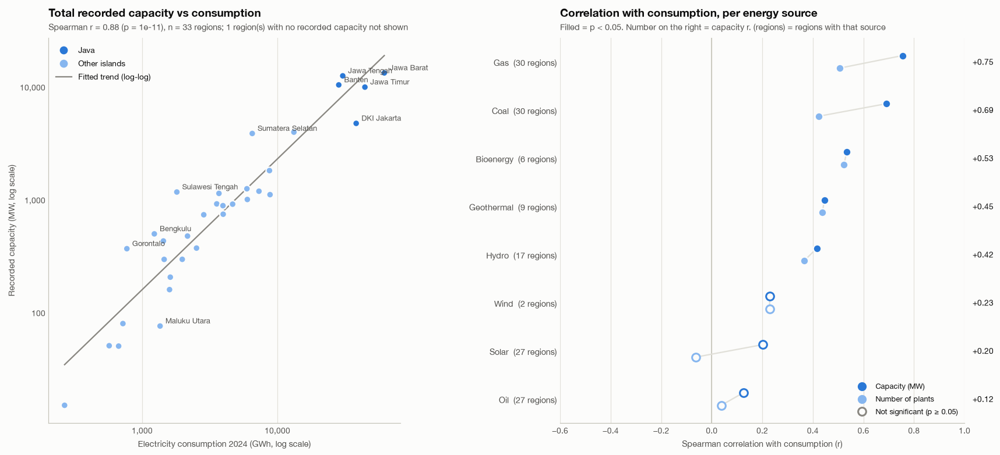

In [38]:
fig = plt.figure(figsize=(16, 7), layout="constrained")
fig.get_layout_engine().set(w_pad=0.3, wspace=0.08)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15])
ax_sc, ax_dot = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
LIGHT_BLUE = "#86b6ef"

# A) Total recorded capacity vs consumption, log-log with fitted line
ax = ax_sc
has_cap = base["total_capacity_mw"] > 0
x_c, y_c = base.loc[has_cap, "consumption_gwh"], base.loc[has_cap, "total_capacity_mw"]
slope, intercept = np.polyfit(np.log10(x_c), np.log10(y_c), 1)
xs = np.logspace(np.log10(x_c.min()), np.log10(x_c.max()), 50)
ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color=MUTED, linewidth=1.5, zorder=1, label="Fitted trend (log-log)")
ax.scatter(x_c, y_c, s=60, color=np.where(base.loc[has_cap, "island"] == "Java", BLUE, LIGHT_BLUE),
           edgecolors=SURFACE, linewidths=1.5, zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(fmt_num)); ax.yaxis.set_major_formatter(FuncFormatter(fmt_num))
ax.grid(axis="both")
# Label the points furthest from the trend line, plus the largest consumers
resid = np.log10(y_c) - (intercept + slope * np.log10(x_c))
to_label = resid.abs().nlargest(5).index.union(base.index[(base["island"] == "Java") & has_cap])
for g in to_label:
    ax.annotate(display_name(g), (x_c[g], y_c[g]), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("Electricity consumption 2024 (GWh, log scale)")
ax.set_ylabel("Recorded capacity (MW, log scale)")
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=BLUE, label="Java"),
                   plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=LIGHT_BLUE, label="Other islands"),
                   plt.Line2D([], [], color=MUTED, linewidth=1.5, label="Fitted trend (log-log)")], loc="upper left")
r_all = overall.loc["Recorded capacity (MW)"]
zero_cap = (~has_cap).sum()
chart_title(ax, "Total recorded capacity vs consumption",
            f"Spearman r = {r_all.spearman_r:.2f} (p = {r_all.spearman_p:.1g}), n = {has_cap.sum()} regions"
            + (f"; {zero_cap} region(s) with no recorded capacity not shown" if zero_cap else ""))

# B) Spearman r per energy source: capacity vs number of plants
ax = ax_dot
d = by_source_corr.sort_values("capacity_spearman_r")
yy = np.arange(len(d))
ax.axvline(0, color=AXIS, linewidth=1)
for col, pcol, color, offset, label in [("capacity_spearman_r", "capacity_p", BLUE, 0.13, "Capacity (MW)"),
                                         ("count_spearman_r", "count_p", LIGHT_BLUE, -0.13, "Number of plants")]:
    sig = d[pcol] < 0.05
    ax.scatter(d.loc[sig, col], yy[sig.values] + offset, s=80, color=color, edgecolors=SURFACE, linewidths=1.5,
               zorder=3, label=f"{label}")
    ax.scatter(d.loc[~sig, col], yy[(~sig).values] + offset, s=80, facecolors=SURFACE, edgecolors=color,
               linewidths=2, zorder=3)
for i, (s, r) in enumerate(d.iterrows()):
    ax.plot([r.count_spearman_r, r.capacity_spearman_r], [i - 0.13, i + 0.13], color=GRID, linewidth=1.5, zorder=2)
    ax.text(1.02, i, f"{r.capacity_spearman_r:+.2f}", transform=ax.get_yaxis_transform(), va="center",
            fontsize=9, color=INK)
ax.set_yticks(yy, [f"{s.capitalize()}  ({int(r.regions_with_source)} regions)" for s, r in d.iterrows()], fontsize=9.5)
ax.set_xlim(-0.6, 1)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Spearman correlation with consumption (r)")
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=BLUE, label="Capacity (MW)"),
                   plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=LIGHT_BLUE, label="Number of plants"),
                   plt.Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor=SURFACE,
                              markeredgecolor=MUTED, markeredgewidth=2, label="Not significant (p ≥ 0.05)")],
          loc="lower right", fontsize=8.5)
chart_title(ax, "Correlation with consumption, per energy source",
            "Filled = p < 0.05. Number on the right = capacity r. (regions) = regions with that source")
plt.show()

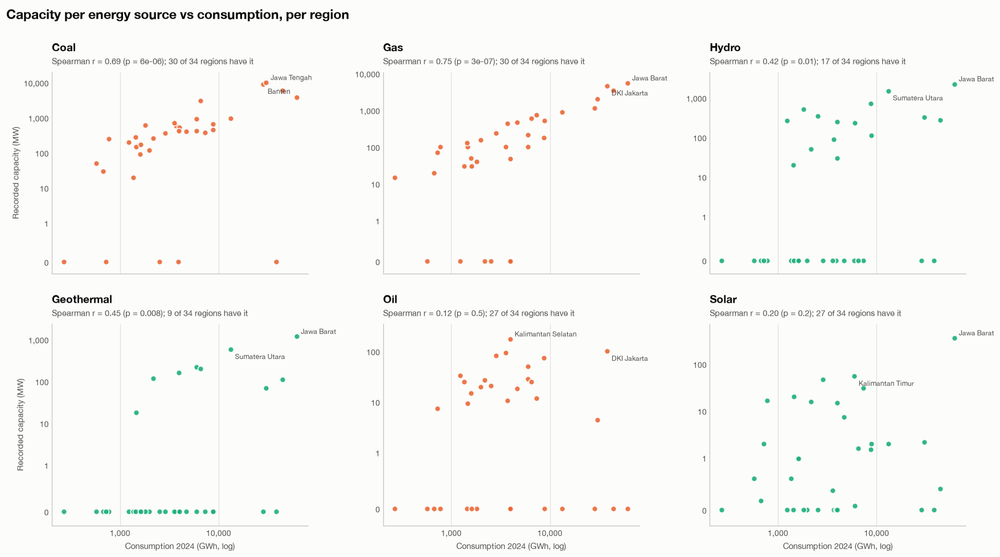

In [39]:
# Small multiples: capacity of each main source vs consumption, per region
main_sources = by_source_corr.sort_values("national_mw_pct", ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, layout="constrained")
fig.get_layout_engine().set(h_pad=0.15, w_pad=0.15)
fig.suptitle("Capacity per energy source vs consumption, per region", x=0.005, ha="left", fontsize=15, fontweight="bold")
for ax, s in zip(axes.flat, main_sources):
    cat = mix.loc[s, "category"]
    v = cap_by_src[s]
    ax.scatter(y, v, s=42, color=COLORS_CAT[cat], edgecolors=SURFACE, linewidths=1.2, zorder=3, alpha=0.9)
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1)
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_num)); ax.yaxis.set_major_formatter(FuncFormatter(fmt_num))
    ax.set_ylim(-0.3, max(v.max() * 2, 10))
    ax.grid(axis="both")
    for k, g in enumerate(v.nlargest(2).index):          # label the two largest; second one below to avoid overlap
        if v[g] > 0:
            ax.annotate(display_name(g), (y[g], v[g]), xytext=(5, 3 if k == 0 else -11), textcoords="offset points",
                        fontsize=8, color=INK2)
    r = by_source_corr.loc[s]
    chart_title(ax, s.capitalize(),
                f"Spearman r = {r.capacity_spearman_r:.2f} (p = {r.capacity_p:.1g}); "
                f"{int(r.regions_with_source)} of {len(base)} regions have it")
for ax in axes[1]:
    ax.set_xlabel("Consumption 2024 (GWh, log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Recorded capacity (MW)")
plt.show()

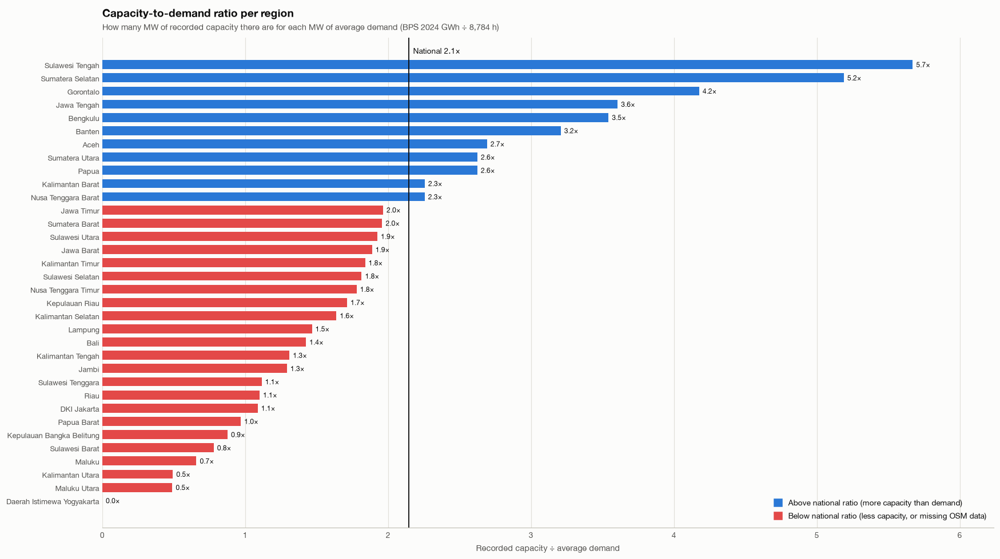

National ratio: 2.14× (recorded capacity / average demand)
Highest ratios: Sulawesi Tengah 5.7×, Sumatera Selatan 5.2×, Gorontalo 4.2×, Jawa Tengah 3.6×, Bengkulu 3.5×
Lowest ratios : Daerah Istimewa Yogyakarta 0.0×, Maluku Utara 0.5×, Kalimantan Utara 0.5×, Maluku 0.7×, Sulawesi Barat 0.8×


In [40]:
# Capacity-to-demand ratio per region: recorded MW / average demand MW
base["avg_demand_mw"] = base["consumption_gwh"] / HOURS_2024 * 1000
base["capacity_to_demand"] = base["total_capacity_mw"] / base["avg_demand_mw"]
national_ratio = base["total_capacity_mw"].sum() / base["avg_demand_mw"].sum()
DIV_HIGH, DIV_LOW = "#2a78d6", "#e34948"      # diverging pair: above / below the national ratio

r_sorted = base.sort_values("capacity_to_demand")
fig, ax = plt.subplots(figsize=(16, 9))
bars = ax.barh([display_name(g) for g in r_sorted.index], r_sorted["capacity_to_demand"],
               color=np.where(r_sorted["capacity_to_demand"] >= national_ratio, DIV_HIGH, DIV_LOW), height=0.68)
ax.bar_label(bars, labels=[f"{v:.1f}×" for v in r_sorted["capacity_to_demand"]], padding=4, fontsize=8, color=INK)
ax.axvline(national_ratio, color=INK, linewidth=1.2)
ax.text(national_ratio, len(r_sorted) - 0.3, f"  National {national_ratio:.1f}×", va="bottom", fontsize=9, color=INK)
ax.set_xlim(0, r_sorted["capacity_to_demand"].max() * 1.1)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("Recorded capacity ÷ average demand")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=DIV_HIGH, label="Above national ratio (more capacity than demand)"),
                   plt.Rectangle((0, 0), 1, 1, color=DIV_LOW, label="Below national ratio (less capacity, or missing OSM data)")],
          loc="lower right", handlelength=1, handleheight=1)
chart_title(ax, "Capacity-to-demand ratio per region",
            "How many MW of recorded capacity there are for each MW of average demand (BPS 2024 GWh ÷ 8,784 h)")
plt.tight_layout()
plt.show()

print(f"National ratio: {national_ratio:.2f}× (recorded capacity / average demand)")
print("Highest ratios:", ", ".join(f"{display_name(g)} {v:.1f}×" for g, v in base["capacity_to_demand"].nlargest(5).items()))
print("Lowest ratios :", ", ".join(f"{display_name(g)} {v:.1f}×" for g, v in base["capacity_to_demand"].nsmallest(5).items()))

**Interpretation**
1. **Capacity follows demand; the number of plants does not.** Total recorded capacity correlates strongly with consumption (Spearman r ≈ 0.88), much more than the number of plants (r ≈ 0.51). Large plants are built where electricity is used, while many small plants are spread across regions with little demand.
2. **Gas and coal follow demand most closely** (r ≈ 0.75 and 0.69). These large plants supply the main grids and are built near the big load centres (e.g. the gas plants around Jakarta). Some coal capacity is located away from demand, near coal mines or ports.
3. **Hydro and geothermal correlate only moderately** (r ≈ 0.4) and exist in only 17 and 9 regions. Where they are built depends on natural resources (rivers, mountains, volcanoes), not on demand.
4. **Oil (diesel) and solar show no significant correlation.** They are mostly small plants serving isolated islands and remote areas, so they are found in regions with any level of demand. For solar, the number of plants is not related to consumption at all.
5. **Bioenergy and wind should not be over-interpreted:** bioenergy appears in only 6 regions (38 MW in total) and wind in 2, so their correlations are driven by a handful of values and many zeros.
6. **Capacity-to-demand ratio:** regions above the national ratio probably supply their neighbours through the grid (for example Central Java and Banten, which feed the Java–Bali grid that serves Jakarta), or host industrial power plants whose output is not counted in BPS *distributed* electricity. Regions far below it either receive power from other provinces (Yogyakarta has no plants in OSM but is supplied by the Java grid) or are missing plants in OSM.

**Overall:** at province level, capacity and consumption are clearly linked, but a province is not a closed system: grids connect provinces, and resource-based plants are located where the resources are.

### 2.14.1 Which other data would improve this analysis
The correlation above compares **capacity** with **consumption**. The following data would make the comparison more accurate:

| Data | Why it helps | Possible sources |
|---|---|---|
| **Electricity production (GWh) per province and per source** | Compares production with consumption in the same unit (GWh), instead of using capacity as a proxy | PLN Statistics (*Statistik PLN*), Ministry of Energy (ESDM) electricity statistics (*Statistik Ketenagalistrikan*) |
| **Official installed capacity per province and type** | Replaces the incomplete OSM capacity (about a third of plants have no value) | ESDM electricity statistics, PLN's electricity supply plan (*RUPTL*) |
| **Grid system boundaries** | Electricity flows inside interconnected systems (e.g. Java–Madura–Bali, Sumatra), so analysing per grid system is fairer than per province | PLN / RUPTL system maps |
| **Captive (industrial) power plants** | Industrial plants (e.g. at smelters) produce power that is not in BPS *distributed* electricity, which inflates some capacity ratios | ESDM statistics, company reports |
| **Consumption by sector** (household, industry, business) | Shows *what* drives demand in each province | BPS, PLN Statistics |
| **Population and GRDP per province** | Allows per-capita and per-economy comparisons | BPS |

The production data (first row) would be the most valuable addition: with it, the analysis could directly answer which provinces produce more electricity than they consume, by energy source.

### 2.15 Raster analysis: capacity density surface
The maps so far use **vector** data: plants as points and provinces as polygons. Province maps give one value to a whole province, so the result depends on where the borders are and how big each province is. A **raster** divides the country into equal grid cells instead, so the concentration of power plants can be seen wherever it really is, inside or across provinces.

**Method (kernel density on a grid):**
1. **Grid:** a 5 × 5 km grid over Indonesia in **EPSG:6933** (equal-area), so every cell covers the same 25 km².
2. **Rasterize:** add up the recorded capacity (MW) of all plants in each cell, separately for total, fossil and renewable capacity. A fourth raster counts plants (including those without a recorded capacity).
3. **Smooth:** apply a Gaussian filter with σ = 20 km. Each plant's capacity is spread over its surroundings, turning isolated points into a continuous surface. The filter keeps the total MW unchanged.
4. **Units:** MW per 1,000 km² (plants per 1,000 km² for the count raster).
5. **Mask:** cells further than 15 km from land are hidden for display.

**Outputs:** static maps of the four surfaces, a list of the main capacity *hotspots*, GeoTIFF files in `output/` (usable in QGIS or ArcGIS), and density layers in interactive map 1.

The bandwidth (σ) controls the level of detail: a smaller σ shows individual plants, a larger one shows regional patterns. 20 km is a compromise suited to the scale of the whole country.

In [41]:
import rasterio
from rasterio.transform import from_origin
from scipy import ndimage
from scipy.spatial import cKDTree
import shapely

CELL_M = 5_000          # 5 km cells
SIGMA_M = 20_000        # Gaussian bandwidth (standard deviation)
MASK_BUFFER_M = 15_000  # show cells within 15 km of land

# Grid extent from the province boundaries in the equal-area CRS, padded by 100 km
prov_ea = provinces_proj.copy()                       # EPSG:6933
xmin, ymin, xmax, ymax = prov_ea.total_bounds
pad = 100_000
xmin, ymin = np.floor((xmin - pad) / CELL_M) * CELL_M, np.floor((ymin - pad) / CELL_M) * CELL_M
xmax, ymax = np.ceil((xmax + pad) / CELL_M) * CELL_M, np.ceil((ymax + pad) / CELL_M) * CELL_M
n_cols, n_rows = int((xmax - xmin) / CELL_M), int((ymax - ymin) / CELL_M)
transform = from_origin(xmin, ymax, CELL_M, CELL_M)   # top-left origin, north-up
x_edges = np.linspace(xmin, xmax, n_cols + 1)
y_edges = np.linspace(ymin, ymax, n_rows + 1)
print(f"Grid: {n_cols} × {n_rows} cells of {CELL_M / 1000:.0f} km  ({n_cols * n_rows:,} cells)")

# Plant coordinates in the equal-area CRS
pts_ea = plants_final.to_crs(AREA_CRS)
px, py = pts_ea.geometry.x.values, pts_ea.geometry.y.values

def rasterize_sum(mask, weights=None):
    """Sum of weights per cell (row 0 = north)."""
    w = None if weights is None else weights[mask]
    h, _, _ = np.histogram2d(py[mask], px[mask], bins=[y_edges, x_edges], weights=w)
    return h[::-1]                                     # flip so row 0 is the northern edge

cap = plants_final["capacity_mw"].fillna(0).values
has_cap = plants_final["capacity_mw"].notna().values
raw = {
    "total": rasterize_sum(has_cap, cap),
    "fossil": rasterize_sum(has_cap & (plants_final["category"] == "Fossil").values, cap),
    "renewable": rasterize_sum(has_cap & (plants_final["category"] == "Renewable").values, cap),
    "count": rasterize_sum(np.ones(len(plants_final), bool)),
}

# Smooth and convert to density per 1,000 km²
cell_km2 = (CELL_M / 1000) ** 2
sigma_cells = SIGMA_M / CELL_M
density = {k: ndimage.gaussian_filter(v, sigma=sigma_cells, mode="constant") / cell_km2 * 1000
           for k, v in raw.items()}

# Check: smoothing keeps the total (sum of density × area = original sum)
for k in ["total", "count"]:
    before, after = raw[k].sum(), density[k].sum() * cell_km2 / 1000
    print(f"{k:6s}: rasterized {before:,.0f} -> after smoothing {after:,.0f} ({after / before * 100:.1f}% kept)")

# Land mask: cell centres within 15 km of a province polygon
land = shapely.union_all(prov_ea.geometry.values).buffer(MASK_BUFFER_M)
cx = xmin + (np.arange(n_cols) + 0.5) * CELL_M
cy = ymax - (np.arange(n_rows) + 0.5) * CELL_M
CX, CY = np.meshgrid(cx, cy)
land_mask = shapely.contains_xy(land, CX, CY)
print(f"Cells on or near land: {land_mask.sum():,} of {land_mask.size:,}")

Grid: 929 × 471 cells of 5 km  (437,559 cells)
total : rasterized 74,706 -> after smoothing 74,706 (100.0% kept)
count : rasterized 638 -> after smoothing 638 (100.0% kept)


Cells on or near land: 110,209 of 437,559


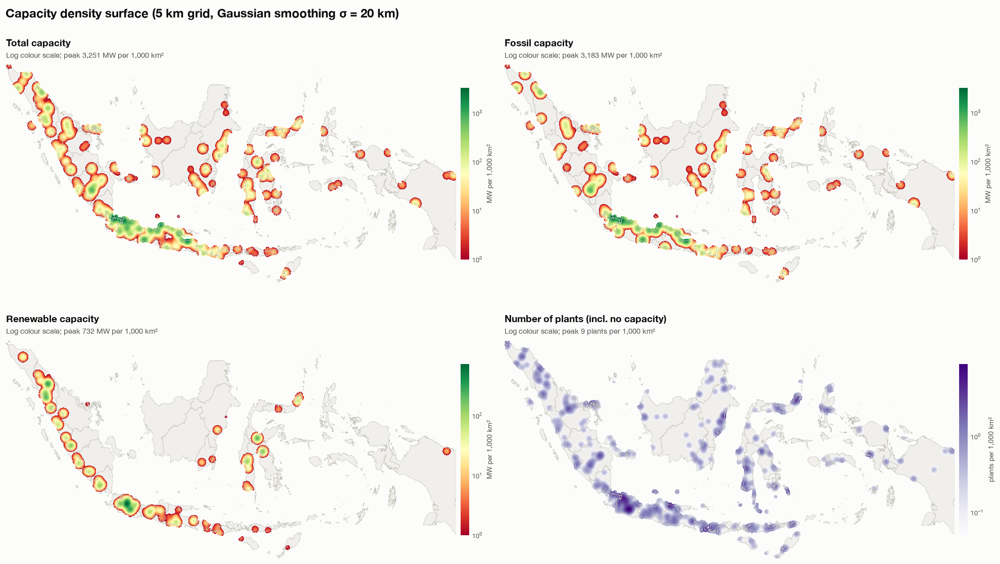

In [42]:
from matplotlib.colors import LogNorm

layers = [("total", "Total capacity", "RdYlGn", "MW per 1,000 km²"),       # capacity: red (low) -> green (high)
          ("fossil", "Fossil capacity", "RdYlGn", "MW per 1,000 km²"),
          ("renewable", "Renewable capacity", "RdYlGn", "MW per 1,000 km²"),
          ("count", "Number of plants (incl. no capacity)", "Purples", "plants per 1,000 km²")]
extent = [xmin, xmax, ymin, ymax]
DISPLAY_FLOOR = {"total": 1, "fossil": 1, "renewable": 1, "count": 0.05}   # hide near-zero values

fig, axes = plt.subplots(2, 2, figsize=(18, 10.5), layout="constrained")
fig.get_layout_engine().set(h_pad=0.15, w_pad=0.1)
fig.suptitle("Capacity density surface (5 km grid, Gaussian smoothing σ = 20 km)", x=0.005, ha="left",
             fontsize=16, fontweight="bold")
for ax, (key, title, cmap_name, unit) in zip(axes.flat, layers):
    d = np.where(land_mask, density[key], np.nan)
    floor = DISPLAY_FLOOR[key]
    d = np.where(d >= floor, d, np.nan)
    prov_ea.plot(ax=ax, color="#f0efec", edgecolor="none", zorder=1)                 # land background
    im = ax.imshow(d, extent=extent, origin="upper", cmap=cmap_name, zorder=2,
                   norm=LogNorm(vmin=floor, vmax=np.nanmax(d)), interpolation="nearest")
    prov_ea.boundary.plot(ax=ax, color=AXIS, linewidth=0.4, zorder=3)                # borders on top
    cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.01)
    cb.set_label(unit, fontsize=9, color=INK2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, labelsize=8.5)
    ax.set_xlim(prov_ea.total_bounds[[0, 2]]); ax.set_ylim(prov_ea.total_bounds[[1, 3]])
    ax.set_axis_off()
    peak = np.nanmax(d)
    chart_title(ax, title, f"Log colour scale; peak {peak:,.0f} {unit}")
plt.show()

In [43]:
# Hotspots: local maxima of the total capacity surface
tot = np.where(land_mask, density["total"], 0)
window = int(2 * sigma_cells) * 2 + 1                       # peaks at least ~40 km apart
peaks = (tot == ndimage.maximum_filter(tot, size=window)) & (tot > 50)
rows, cols = np.nonzero(peaks)
hx, hy = xmin + (cols + 0.5) * CELL_M, ymax - (rows + 0.5) * CELL_M

# For each hotspot: recorded MW within 50 km, number of plants, and the largest plant nearby
tree = cKDTree(np.column_stack([px, py]))
records = []
for r, c, x, y in zip(rows, cols, hx, hy):
    idx = tree.query_ball_point([x, y], r=50_000)
    near = plants_final.iloc[idx]
    big = near.loc[near["capacity_mw"].idxmax()] if near["capacity_mw"].notna().any() else None
    lonlat = gpd.GeoSeries(gpd.points_from_xy([x], [y]), crs=AREA_CRS).to_crs("EPSG:4326").iloc[0]
    records.append({
        "peak_mw_per_1000km2": tot[r, c],
        "mw_within_50km": near["capacity_mw"].sum(),
        "plants_within_50km": len(near),
        "fossil_share_pct": near.loc[near["category"] == "Fossil", "capacity_mw"].sum()
                            / max(near["capacity_mw"].sum(), 1e-9) * 100,
        "province": big["province"] if big is not None else None,          # province of the largest plant
        "largest_plant": f"{big['name']} ({big['capacity_mw']:,.0f} MW, {big['source']})" if big is not None else "-",
        "lat": lonlat.y, "lon": lonlat.x,
    })
hotspots = (pd.DataFrame(records).sort_values("mw_within_50km", ascending=False)
            .reset_index(drop=True))
hotspots.index = hotspots.index + 1
hotspots.index.name = "rank"
top_hot = hotspots.head(10)
display(top_hot.round({"peak_mw_per_1000km2": 0, "mw_within_50km": 0, "fossil_share_pct": 0, "lat": 3, "lon": 3}))

# Share of national capacity in the top hotspots (each plant counted once, even where circles overlap)
in_top = set()
top_xy = top_hot[["lon", "lat"]].values
top_ea = gpd.GeoSeries(gpd.points_from_xy(top_xy[:, 0], top_xy[:, 1]), crs="EPSG:4326").to_crs(AREA_CRS)
for pt in top_ea:
    in_top.update(tree.query_ball_point([pt.x, pt.y], r=50_000))
share_top = plants_final.iloc[sorted(in_top)]["capacity_mw"].sum() / plants_final["capacity_mw"].sum() * 100
print(f"The {len(top_hot)} largest hotspots (within 50 km) hold {share_top:.0f}% of all recorded capacity, "
      f"from {len(in_top)} of {len(plants_final)} plants. Neighbouring hotspots can share plants; "
      f"the MW per hotspot in the table may therefore overlap.")

,peak_mw_per_1000km2,mw_within_50km,plants_within_50km,fossil_share_pct,province,largest_plant,lat,lon
rank,,,,,,,,
1,2946.0,10007.0,22,100.0,Jakarta Special Capital Region,"PLTGU Priok (2,720 MW, gas)",-6.106,106.880
2,3251.0,9770.0,11,98.0,Banten,"PLTU Suralaya (4,025 MW, coal)",-5.948,106.051
3,1896.0,4710.0,1,100.0,East Java,"Unit Pembangkit Listrik Paiton (4,710 MW, coal)",-7.724,113.565
4,1850.0,4640.0,1,100.0,Central Java,"PLTU Tanjung Jati B (4,640 MW, coal)",-6.461,110.767
5,1100.0,2791.0,6,100.0,Central Java,"PLTU Cilacap (2,121 MW, coal)",-7.685,109.109
6,791.0,2570.0,7,100.0,South Sumatra,"PLTU Sumsel 8 (1,320 MW, coal)",-3.785,103.771
7,804.0,2070.0,3,97.0,Central Java,"PLTU Batang (2,000 MW, coal)",-6.895,109.782
8,781.0,1989.0,5,99.0,East Java,"PLTGU Gresik (1,924 MW, gas)",-7.171,112.684
9,551.0,1622.0,8,86.0,West Java,"PLTU Cirebon Unit 2 (660 MW, coal)",-6.776,108.591


The 10 largest hotspots (within 50 km) hold 54% of all recorded capacity, from 72 of 638 plants. Neighbouring hotspots can share plants; the MW per hotspot in the table may therefore overlap.


In [44]:
# Save the density surfaces as GeoTIFF (EPSG:6933), e.g. for QGIS
profile = dict(driver="GTiff", height=n_rows, width=n_cols, count=1, dtype="float32",
               crs=AREA_CRS, transform=transform, nodata=np.nan, compress="deflate")
for key in ["total", "fossil", "renewable", "count"]:
    out = np.where(land_mask, density[key], np.nan).astype("float32")
    path = f"output/density_{key}.tif"
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(out, 1)
        dst.update_tags(units="plants per 1000 km2" if key == "count" else "MW per 1000 km2",
                        method=f"Gaussian kernel density, sigma {SIGMA_M / 1000:.0f} km, cell {CELL_M / 1000:.0f} km")
    print(f"{path:32s} {os.path.getsize(path) / 1024:8.1f} KB")

# Re-read check
with rasterio.open("output/density_total.tif") as src:
    print("Re-read:", src.width, "×", src.height, "| CRS:", src.crs, "| max:", f"{np.nanmax(src.read(1)):,.0f}")

output/density_total.tif            270.1 KB
output/density_fossil.tif           226.6 KB
output/density_renewable.tif        185.5 KB
output/density_count.tif            306.6 KB
Re-read: 929 × 471 | CRS: EPSG:6933 | max: 3,251


**Interpretation of the density surfaces**
1. **Capacity is concentrated in a few hotspots.** The total and fossil surfaces show a dense belt along the north coast of Java (Banten, Jakarta, Central and East Java) and a smaller centre in South Sumatra. The hotspot table shows that the ten largest hotspots, each a circle of 50 km, hold more than half of all recorded capacity. These are almost entirely large coal and gas plants.
2. **Fossil hotspots are on the coast.** Large coal and gas plants need cooling water and port access for fuel delivery, so they sit along the coast close to the big cities.
3. **Renewable capacity follows the mountains.** The renewable surface forms a chain along the Barisan mountains of western Sumatra and clusters in West Java and Sulawesi: hydro and geothermal plants located where rivers and volcanoes are, not where demand is. This matches the weak correlation of renewables with consumption (section 2.14).
4. **The number of plants is spread much more evenly than capacity.** The plant count surface covers almost every island, including eastern Indonesia, while capacity is concentrated in western Indonesia. Many places depend on small plants with little capacity.
5. **The raster removes the effect of province borders.** For example, the Jakarta hotspot extends into Banten and West Java, which a province map would split into three separate values.

**Limitations:** plants without a recorded capacity are missing from the MW surfaces (they are included in the plant count surface); the result depends on the chosen bandwidth (σ = 20 km); and a density surface shows where capacity is *located*, not where its electricity is *used*, because power flows through the grid.

### 2.16 Spatial visualization (interactive maps)

Three interactive maps (built with `folium` / Leaflet). Use the **layer panel at the top right** to switch layers, hover over a plant or province for details, and zoom with the mouse wheel.

1. **Power plant locations by energy source**: one layer per source (coal and gas are on by default), plus combined *fossil* and *renewable* layers and the **capacity density surfaces** from the raster analysis (section 2.15). Circle size shows capacity; plants without a recorded capacity are drawn as small hollow circles.
2. **Recorded capacity per province**: one layer at a time (coal, gas, fossil, renewable, total capacity, renewable share of capacity, and plant density per 10,000 km²); the legend changes with the layer.
3. **Electricity consumption per province**: consumption (BPS 2024), consumption per km², and the capacity-to-demand ratio, with an optional layer of all power plants on top.

Each map is also saved as an HTML file in `output/`, so it can be opened in any browser or shared. The maps need an internet connection for the background map. GitHub does not display interactive maps; open the HTML files from `output/` instead.

In [45]:
import html as _html
import folium
from folium.plugins import GroupedLayerControl
from branca.element import MacroElement, Template
from matplotlib.colors import to_hex

# Colours per energy source (identity), and per category (same as the static charts)
SOURCE_COLORS = {"coal": "#3b3b38", "gas": "#6250d6", "oil": "#e87ba4", "hydro": "#2a78d6",
                 "geothermal": "#e34948", "solar": "#eda100", "wind": "#86b6ef", "bioenergy": "#008300",
                 "unknown": "#b5b3ad"}
MAP_CENTER, MAP_ZOOM = [-2.5, 118.0], 5
CAPACITY_CMAP, CONSUMPTION_CMAP = "RdYlGn", "Blues"   # supply: red (low) -> green (high); demand: blues
NONE_FILL = "#ffffff"   # provinces with zero: white, so they stand out from the grey basemap

def base_map():
    """Light, quiet background; tiles are not a selectable layer so layer radios only switch data."""
    m = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles=None, control_scale=True, prefer_canvas=True)
    folium.TileLayer("Esri.WorldGrayCanvas", name="Background", control=False).add_to(m)   # free, no API key
    return m

def capacity_radius(mw):
    """Circle radius in pixels: area grows with capacity; unknown capacity -> small circle."""
    return 3.0 if pd.isna(mw) else 3.0 + np.sqrt(mw) * 0.28

def class_bins(values, n=5):
    """Class breaks from quantiles of the positive values, rounded to 2 significant digits."""
    pos = np.asarray(values)[np.asarray(values) > 0]
    qs = np.quantile(pos, np.linspace(0, 1, n + 1))
    nice = [float(f"{q:.2g}") for q in qs]
    nice[0], nice[-1] = 0, max(nice[-1], pos.max())
    return sorted(set(nice))

def class_colors(cmap_name, k, start=0.3):
    cmap = plt.get_cmap(cmap_name)
    return [to_hex(cmap(x)) for x in np.linspace(start, 0.95, k)]

def fmt_class(lo, hi):
    f = lambda v: f"{v:,.0f}" if v >= 10 else f"{v:,.1f}"
    return f"up to {f(hi)}" if lo == 0 else f"{f(lo)} – {f(hi)}"

def add_switching_legends(m, legends, start):
    """One legend per radio layer; JS shows the legend of the active layer only.
    legends = {layer_name: (title, [(color, label), ...])}"""
    mid = m.get_name()
    divs = []
    for name, (title, items) in legends.items():
        rows = "".join(f"<div style='display:flex;align-items:center;gap:6px;margin:2px 0'>"
                       f"<span style='width:14px;height:14px;background:{c};display:inline-block;"
                       f"border:1px solid rgba(0,0,0,.1)'></span>{_html.escape(l)}</div>" for c, l in items)
        divs.append(f"<div class='lg-{mid}' data-layer='{_html.escape(name)}' style='display:"
                    f"{'block' if name == start else 'none'}'><b>{_html.escape(title)}</b>{rows}</div>")
    box = ("<div style='position:fixed;bottom:40px;left:12px;z-index:9999;background:rgba(252,252,251,.94);"
           "padding:10px 12px;border-radius:6px;font:12px Helvetica Neue,Arial,sans-serif;color:#0b0b0b;"
           "box-shadow:0 1px 4px rgba(0,0,0,.15)'>" + "".join(divs) + "</div>")
    el = MacroElement()
    el._template = Template("""
        {% macro html(this, kwargs) %}""" + box + """{% endmacro %}
        {% macro script(this, kwargs) %}
        """ + mid + """.on('baselayerchange', function (e) {
            document.querySelectorAll('.lg-""" + mid + """').forEach(function (d) {
                d.style.display = (d.getAttribute('data-layer') === e.name) ? 'block' : 'none';
            });
        });
        {% endmacro %}""")
    m.get_root().add_child(el)

def add_static_legend(m, html_body):
    el = MacroElement()
    el._template = Template("{% macro html(this, kwargs) %}<div style='position:fixed;bottom:40px;left:12px;"
                            "z-index:9999;background:rgba(252,252,251,.94);padding:10px 12px;border-radius:6px;"
                            "font:12px Helvetica Neue,Arial,sans-serif;color:#0b0b0b;"
                            "box-shadow:0 1px 4px rgba(0,0,0,.15)'>" + html_body + "</div>{% endmacro %}")
    m.get_root().add_child(el)

def choropleth_layer(gdf, column, name, cmap_name, tooltip_fields, tooltip_aliases, show=False, bins=None, colors=None,
                     zero_is_data=False, none_label="0 / none recorded"):
    """A radio layer: provinces coloured in classes; 0 shown as 'none recorded'."""
    bins = bins or class_bins(gdf[column])
    colors = colors or class_colors(cmap_name, len(bins) - 1)
    def style(feature):  # noqa: E306
        v = feature["properties"][column]
        if v is None or (v <= 0 and not zero_is_data):
            fill = NONE_FILL
        else:
            idx = min(np.searchsorted(bins, v, side="right") - 1, len(colors) - 1)
            fill = colors[max(idx, 0)]
        return {"fillColor": fill, "color": "#9aa0a6" if fill == NONE_FILL else "#ffffff", "weight": 0.8,
                "fillOpacity": 0.85}
    fg = folium.FeatureGroup(name=name, overlay=False, show=show)
    folium.GeoJson(gdf, style_function=style,
                   highlight_function=lambda f: {"weight": 2.5, "color": "#0b0b0b"},
                   tooltip=folium.GeoJsonTooltip(fields=tooltip_fields, aliases=tooltip_aliases, localize=True,
                                                 sticky=True)).add_to(fg)
    items = [(NONE_FILL, none_label)] + [(c, fmt_class(lo, hi)) for c, lo, hi in zip(colors, bins[:-1], bins[1:])]
    return fg, items

def plant_tooltip(r):
    cap = f"{r.capacity_mw:,.1f} MW" if pd.notna(r.capacity_mw) else "not recorded"
    return (f"<b>{_html.escape(str(r.name))}</b><br>{r.source.capitalize()} · {r.category}<br>"
            f"Capacity: {cap}<br>Province: {_html.escape(str(r.province))}")

# Province geometries simplified for the web (about 2 km tolerance) to keep the maps light
prov_web = summary[["province", "geometry"]].copy()
prov_web["geometry"] = prov_web.geometry.simplify(0.02, preserve_topology=True)
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.transform import array_bounds

def density_overlay(key, cmap_name, name, show=False):
    """Reproject a density raster to Web Mercator and add it as a semi-transparent image layer.
    Low values are transparent; opacity and colour grow with density (log scale)."""
    arr = np.where(land_mask, density[key], np.nan).astype("float32")
    t, w, h = calculate_default_transform(AREA_CRS, "EPSG:3857", n_cols, n_rows, xmin, ymin, xmax, ymax)
    dst = np.full((h, w), np.nan, dtype="float32")
    reproject(arr, dst, src_transform=transform, src_crs=AREA_CRS, dst_transform=t, dst_crs="EPSG:3857",
              resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    floor = DISPLAY_FLOOR[key]
    vmax = float(np.nanmax(dst))
    valid_px = np.isfinite(dst) & (dst >= floor)
    scaled = np.ma.getdata(LogNorm(vmin=floor, vmax=vmax)(np.clip(np.where(valid_px, dst, floor), floor, vmax)))
    rgba = plt.get_cmap(cmap_name)(scaled)
    rgba[..., 3] = np.where(valid_px, 0.35 + 0.6 * scaled, 0)
    west, south, east, north = array_bounds(h, w, t)
    corners = gpd.GeoSeries(gpd.points_from_xy([west, east], [south, north]), crs="EPSG:3857").to_crs("EPSG:4326")
    bounds = [[corners.iloc[0].y, corners.iloc[0].x], [corners.iloc[1].y, corners.iloc[1].x]]
    fg = folium.FeatureGroup(name=name, show=show)
    folium.raster_layers.ImageOverlay(image=(rgba * 255).astype(np.uint8), bounds=bounds, mercator_project=False,
                                      interactive=False, pane="rasterPane").add_to(fg)
    return fg

print("Helpers ready.")

Helpers ready.


**Map 1: power plant locations by energy source.** Coal and gas are shown first; tick the other sources, the combined *All fossil* / *All renewable* layers, or a *density surface* layer (raster) in the layer panel.


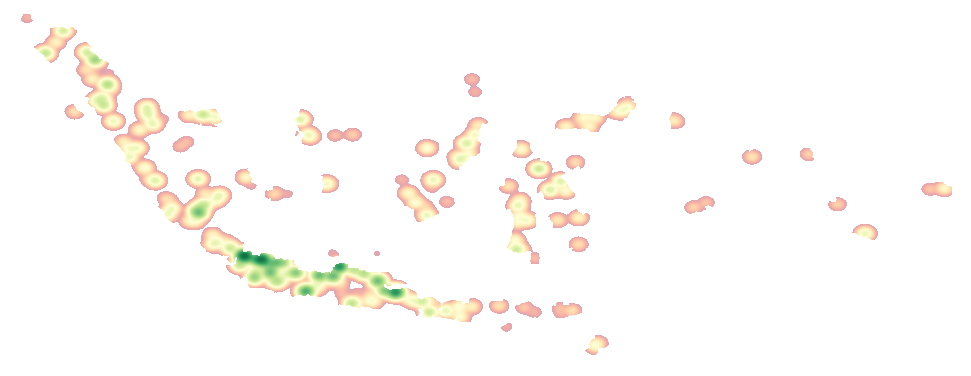
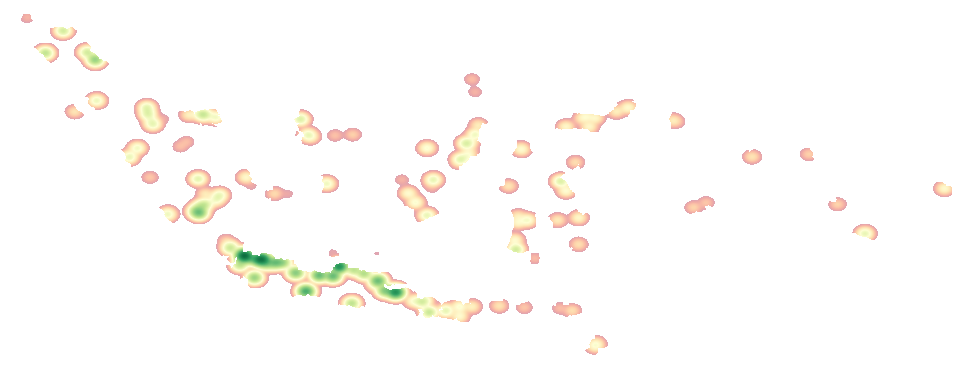
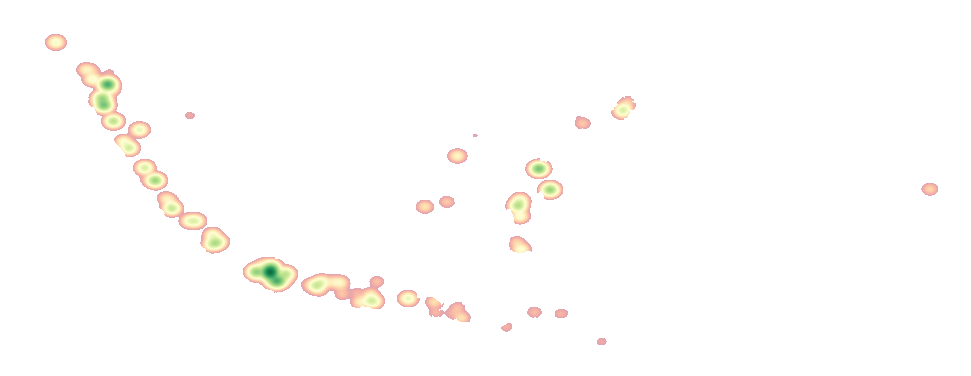
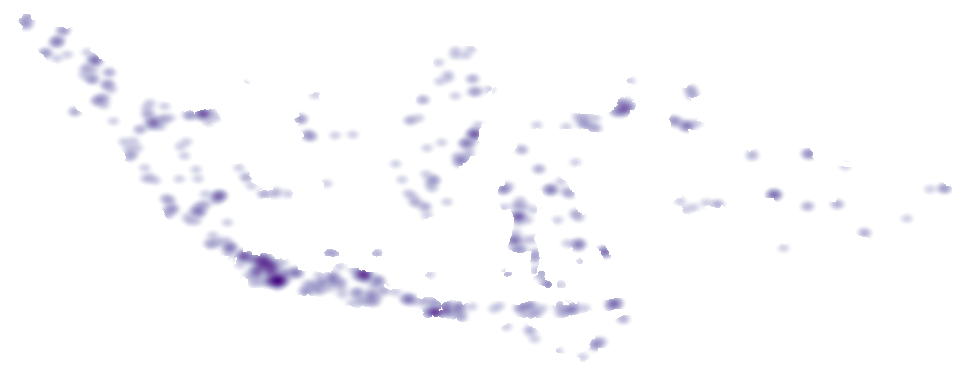

In [46]:
m1 = base_map()
folium.map.CustomPane("rasterPane", z_index=350).add_to(m1)   # raster layers sit below the plant circles

# Boundaries: added first so the plant circles are drawn on top of the lines
border_layer = folium.FeatureGroup(name="Province & national borders", show=True)
folium.GeoJson(prov_web[["province", "geometry"]],
               style_function=lambda f: {"fill": False, "color": "#8a8983", "weight": 0.7, "opacity": 0.9},
               tooltip=folium.GeoJsonTooltip(fields=["province"], aliases=["Province"], sticky=True)).add_to(border_layer)
national = gpd.GeoDataFrame(geometry=[shapely.union_all(prov_web.geometry.values)], crs=prov_web.crs)
folium.GeoJson(national, style_function=lambda f: {"fill": False, "color": "#52514e", "weight": 1.6, "opacity": 0.9},
               interactive=False).add_to(border_layer)
border_layer.add_to(m1)
pts = plants_final.copy()
pts["radius"] = pts["capacity_mw"].apply(capacity_radius)
pts = pts.sort_values("capacity_mw", ascending=False, na_position="last")   # small circles drawn on top

def plant_layer(sub, name, color, show):
    fg = folium.FeatureGroup(name=name, show=show)
    for r in sub.itertuples():
        known = pd.notna(r.capacity_mw)
        folium.CircleMarker([r.latitude, r.longitude], radius=r.radius,
                            color="#ffffff" if known else color, weight=0.8 if known else 1.5,
                            fill=True, fill_color=color, fill_opacity=0.8 if known else 0.15,
                            tooltip=plant_tooltip(r)).add_to(fg)
    return fg

source_order = list(mix.index)   # by recorded capacity, 'unknown' last
source_layers, category_layers = [], []
for s in source_order:
    sub = pts[pts["source"] == s]
    fg = plant_layer(sub, f"{s.capitalize()} ({len(sub)})", SOURCE_COLORS[s], show=s in ("coal", "gas"))
    fg.add_to(m1); source_layers.append(fg)
for cat in ["Fossil", "Renewable"]:
    sub = pts[pts["category"] == cat]
    fg = plant_layer(sub, f"All {cat.lower()} ({len(sub)})", COLORS_CAT[cat], show=False)
    fg.add_to(m1); category_layers.append(fg)

density_layers = []
for key, cmap_name, label in [("total", CAPACITY_CMAP, "Total capacity density"),
                              ("fossil", CAPACITY_CMAP, "Fossil capacity density"),
                              ("renewable", CAPACITY_CMAP, "Renewable capacity density"),
                              ("count", "Purples", "Plant count density")]:
    fg = density_overlay(key, cmap_name, label)
    fg.add_to(m1); density_layers.append(fg)

GroupedLayerControl(groups={"Energy source": source_layers, "Category": category_layers,
                            "Density surface (raster, section 2.15)": density_layers,
                            "Boundaries": [border_layer]},
                    exclusive_groups=False, collapsed=False).add_to(m1)

swatch = lambda c, l: (f"<div style='display:flex;align-items:center;gap:6px;margin:2px 0'><span style='width:11px;"
                       f"height:11px;border-radius:50%;background:{c};display:inline-block'></span>{l}</div>")
add_static_legend(m1, "<b>Energy source</b>" + "".join(swatch(SOURCE_COLORS[s], s.capitalize()) for s in source_order)
                  + "<div style='margin-top:6px'><b>Category layers</b></div>"
                  + swatch(COLORS_CAT["Fossil"], "All fossil") + swatch(COLORS_CAT["Renewable"], "All renewable")
                  + "<div style='margin-top:6px;color:#52514e'>Circle size = capacity (MW)<br>"
                    "Hollow = capacity not recorded</div>"
                  + "<div style='margin-top:6px;color:#52514e'>Capacity density: red → yellow → green<br>"
                    "= low → high (log scale)<br>Plant count density: light → dark purple</div>")
m1.save("output/map_1_power_plants_by_source.html")
m1

**Map 2: recorded capacity per province.** Choose one layer at a time: coal, gas, then fossil, renewable and total capacity, followed by the renewable share of capacity and the plant density (plants per 10,000 km², which corrects for province size). Hover over a province to see all values.

In [47]:
# Capacity per province and energy source
cap_prov = plants_final.pivot_table(index="province", columns="source", values="capacity_mw", aggfunc="sum", fill_value=0)
prov_cap = prov_web.merge(cap_prov, left_on="province", right_index=True, how="left")
for s in SOURCE_COLORS:
    if s not in prov_cap:
        prov_cap[s] = 0.0
prov_cap = prov_cap.fillna(0)
prov_cap["fossil"] = prov_cap[FOSSIL].sum(axis=1)
prov_cap["renewable"] = prov_cap[RENEWABLE].sum(axis=1)
prov_cap["total"] = prov_cap[list(SOURCE_COLORS)].sum(axis=1)
prov_cap["renewable_share"] = np.where(prov_cap["total"] > 0, prov_cap["renewable"] / prov_cap["total"] * 100, np.nan)
prov_cap = prov_cap.merge(summary[["province", "plant_count", "density_per_10k_km2"]], on="province")
num_cols = ["coal", "gas", "fossil", "renewable", "total", "renewable_share", "plant_count", "density_per_10k_km2"]
prov_cap[num_cols] = prov_cap[num_cols].round(1)

tip_fields = ["province", "coal", "gas", "oil", "fossil", "hydro", "geothermal", "solar", "wind", "bioenergy",
              "renewable", "total", "renewable_share", "plant_count", "density_per_10k_km2"]
tip_aliases = ["Province", "Coal (MW)", "Gas (MW)", "Oil (MW)", "Fossil total (MW)", "Hydro (MW)", "Geothermal (MW)",
               "Solar (MW)", "Wind (MW)", "Bioenergy (MW)", "Renewable total (MW)", "Total capacity (MW)",
               "Renewable share of MW (%)", "Power plants", "Plants per 10,000 km²"]
src_cols = ["oil", "hydro", "geothermal", "solar", "wind", "bioenergy"]
prov_cap[src_cols] = prov_cap[src_cols].round(1)

m2 = base_map()
layers2 = [("coal", "Coal capacity", CAPACITY_CMAP), ("gas", "Gas capacity", CAPACITY_CMAP),
           ("fossil", "Fossil capacity", CAPACITY_CMAP), ("renewable", "Renewable capacity", CAPACITY_CMAP),
           ("total", "Total capacity", CAPACITY_CMAP)]
legends2 = {}
for i, (col, name, cmap_name) in enumerate(layers2):
    colors = class_colors(cmap_name, len(class_bins(prov_cap[col])) - 1, start=0.05)
    fg, items = choropleth_layer(prov_cap, col, name, cmap_name, tip_fields, tip_aliases, show=(i == 0), colors=colors)
    fg.add_to(m2)
    legends2[name] = (f"{name} (MW)", items)
# Renewable share of recorded capacity: 0% is a real value; provinces without capacity are 'no data'
name = "Renewable share of capacity"
fg, items = choropleth_layer(prov_cap, "renewable_share", name, None, tip_fields, tip_aliases,
                             bins=[0, 10, 25, 50, 75, 100], colors=class_colors(CAPACITY_CMAP, 5, start=0.05),
                             zero_is_data=True, none_label="no recorded capacity")
fg.add_to(m2)
legends2[name] = ("Renewable share of recorded capacity (%)", items)

# Plant density, correcting for province size
name = "Plant density"
fg, items = choropleth_layer(prov_cap, "density_per_10k_km2", name, None, tip_fields, tip_aliases,
                             bins=[0, 2, 4, 6, 10, 20, 100], colors=class_colors(CAPACITY_CMAP, 6, start=0.05))
fg.add_to(m2)
legends2[name] = ("Power plants per 10,000 km²", items)

folium.LayerControl(collapsed=False).add_to(m2)
add_switching_legends(m2, legends2, start=layers2[0][1])
m2.save("output/map_2_capacity_by_province.html")
m2

**Map 3: electricity consumption per province (BPS 2024).** Layers: total consumption, consumption per km², and the capacity-to-demand ratio (recorded capacity ÷ average demand; blue = above the national ratio, red = below). Tick *Power plants* to show all plants on top. The new Papua provinces are merged with their parents, as in the BPS data.

In [48]:
reg_web = regions[["group", "map_provinces", "consumption_gwh", "national_consumption_share_pct",
                    "consumption_mwh_per_km2", "total_capacity_mw", "plant_count", "geometry"]].copy()
reg_web["geometry"] = reg_web.geometry.simplify(0.02, preserve_topology=True)
reg_web["region"] = reg_web["group"].map(display_name)
reg_web = reg_web.merge(base[["avg_demand_mw", "capacity_to_demand"]], left_on="group", right_index=True, how="left")
for c, d in [("consumption_gwh", 0), ("avg_demand_mw", 0), ("total_capacity_mw", 0), ("capacity_to_demand", 2),
             ("consumption_mwh_per_km2", 1)]:
    reg_web[c] = reg_web[c].round(d)

tip3_fields = ["region", "consumption_gwh", "national_consumption_share_pct", "avg_demand_mw",
               "consumption_mwh_per_km2", "total_capacity_mw", "capacity_to_demand", "plant_count"]
tip3_aliases = ["Region", "Consumption 2024 (GWh)", "Share of national (%)", "Average demand (MW)",
                "Consumption per km² (MWh)", "Recorded capacity (MW)", "Capacity ÷ average demand", "Power plants"]

m3 = base_map()
legends3 = {}
fg, items = choropleth_layer(reg_web, "consumption_gwh", "Consumption (GWh)", CONSUMPTION_CMAP, tip3_fields, tip3_aliases,
                             show=True, bins=[0, 1000, 2500, 5000, 10000, 30000, 65000])
fg.add_to(m3); legends3["Consumption (GWh)"] = ("Electricity consumption 2024 (GWh)", items)
fg, items = choropleth_layer(reg_web, "consumption_mwh_per_km2", "Consumption per km²", CONSUMPTION_CMAP, tip3_fields,
                             tip3_aliases)
fg.add_to(m3); legends3["Consumption per km²"] = ("Consumption per km² (MWh)", items)

# Diverging classes around the national ratio: red below, blue above
nat = round(national_ratio, 2)
ratio_bins = [0, 1, 1.5, nat, 3, 4, max(6, float(reg_web["capacity_to_demand"].max()))]
ratio_colors = [to_hex(plt.get_cmap("RdBu")(x)) for x in [0.08, 0.22, 0.36, 0.68, 0.81, 0.94]]
fg, items = choropleth_layer(reg_web, "capacity_to_demand", "Capacity-to-demand ratio", None, tip3_fields,
                             tip3_aliases, bins=ratio_bins, colors=ratio_colors)
fg.add_to(m3)
items = [(c, l + ("  (below national)" if i < 3 else "  (above national)")) for i, (c, l) in enumerate(items[1:])]
legends3["Capacity-to-demand ratio"] = (f"Capacity ÷ average demand (national {nat:.1f}×)",
                                        [(NONE_FILL, "0 / no recorded capacity")] + items)

# Optional overlay: all plants as small dots by category
fg_pts = folium.FeatureGroup(name="Power plants (all)", show=False)
for r in pts.itertuples():
    folium.CircleMarker([r.latitude, r.longitude], radius=2.5, color=COLORS_CAT[r.category], weight=0,
                        fill=True, fill_opacity=0.85, tooltip=plant_tooltip(r)).add_to(fg_pts)
fg_pts.add_to(m3)

folium.LayerControl(collapsed=False).add_to(m3)
add_switching_legends(m3, legends3, start="Consumption (GWh)")
m3.save("output/map_3_consumption.html")
m3

### 2.17 Data export
Tabular results are exported to **CSV**, spatial results to **GeoJSON** and **GeoPackage** (three layers in one file). The files are then read back to confirm the export succeeded.

In [49]:
# Tabular (without geometry)
plants_final.drop(columns="geometry").to_csv("output/power_plants_clean.csv", index=False)
summary.drop(columns="geometry").to_csv("output/province_summary.csv", index=False)
regions.drop(columns="geometry").to_csv("output/consumption_vs_plants.csv", index=False)

# Spatial
export_cols = ["osm_type", "osm_id", "name", "source", "category", "hybrid", "source_from_name",
               "capacity_mw", "capacity_class", "operator", "province", "geometry"]
missing_cols = [c for c in export_cols if c not in plants_final.columns]
if missing_cols:
    print("Columns not in the data, skipped in export:", missing_cols)
plants_export = plants_final[[c for c in export_cols if c in plants_final.columns]].copy()
plants_export["capacity_class"] = plants_export["capacity_class"].astype("string")
if "operator" in plants_export:
    plants_export["operator"] = plants_export["operator"].astype("string")

plants_export.to_file("output/power_plants.geojson", driver="GeoJSON")
plants_export.to_file("output/energy_indonesia.gpkg", layer="power_plants", driver="GPKG")
summary.to_file("output/energy_indonesia.gpkg", layer="provinces", driver="GPKG")
regions.to_file("output/energy_indonesia.gpkg", layer="consumption_vs_plants", driver="GPKG")

# Verification
for f in sorted(os.listdir("output")):
    print(f"{f:32s} {os.path.getsize(os.path.join('output', f))/1024:10.1f} KB")
import pyogrio
print("\nLayers in GPKG:", [l[0] for l in pyogrio.list_layers("output/energy_indonesia.gpkg")])
check = gpd.read_file("output/energy_indonesia.gpkg", layer="provinces")
print("\nRe-read check of GPKG (provinces layer):", check.shape, "| CRS:", check.crs)

consumption_vs_plants.csv               2.6 KB
density_count.tif                     306.6 KB
density_fossil.tif                    226.6 KB
density_renewable.tif                 185.5 KB
density_total.tif                     270.1 KB
energy_indonesia.gpkg                4020.0 KB
map_1_power_plants_by_source.html     2056.1 KB
map_2_capacity_by_province.html      2997.0 KB
map_3_consumption.html               1779.9 KB
power_plants.geojson                  241.7 KB
power_plants_clean.csv                 93.0 KB
province_summary.csv                    3.5 KB

Layers in GPKG: ['power_plants', 'provinces', 'consumption_vs_plants']

Re-read check of GPKG (provinces layer): (34, 14) | CRS: EPSG:4326


In [50]:
# (Optional) download the exported files to your computer when running in Colab
try:
    from google.colab import files
    import shutil
    shutil.make_archive("export_results", "zip", "output")
    files.download("export_results.zip")
except ImportError:
    print("Not running in Colab, skipping download.")

Not running in Colab, skipping download.


---
## 3. Brief Report: Output, Evaluation, and Interpretation of Results

The next cell generates a summary of figures directly from the processed data, so the figures in the report always match the data that was processed.

In [51]:
n_total = len(plants_final)
cat = plants_final["category"].value_counts()
known_total = cat.get("Renewable", 0) + cat.get("Fossil", 0)
top_count = summary.sort_values("plant_count", ascending=False).iloc[0]
top_density = summary.sort_values("density_per_10k_km2", ascending=False).iloc[0]
top_sources = plants_final.loc[plants_final["source"] != "unknown", "source"].value_counts()
zero = summary.loc[summary["plant_count"] == 0, "province"].tolist()

print("=== RESULTS SUMMARY ===")
print(f"Raw OSM data                  : {len(df):,} objects")
print(f"Power plants after cleaning   : {n_total:,} points in {summary['plant_count'].gt(0).sum()} provinces")
print(f"Known energy source           : {known_total:,} ({known_total/n_total*100:.1f}%); "
      f"{int(plants_final['source_from_name'].sum()):,} of them filled from the name")
print(f"Renewable vs Fossil           : {cat.get('Renewable',0):,} vs {cat.get('Fossil',0):,} "
      f"({cat.get('Renewable',0)/max(known_total,1)*100:.1f}% renewable)")
print(f"Recorded capacity             : {plants_final['capacity_mw'].notna().sum():,} plants, "
      f"total {plants_final['capacity_mw'].sum():,.0f} MW")
print(f"Most common sources           : {', '.join(f'{k} ({v})' for k, v in top_sources.head(3).items())}")
print(f"Province with most plants     : {top_count['province']} ({int(top_count['plant_count'])})")
print(f"Densest province              : {top_density['province']} ({top_density['density_per_10k_km2']} per 10,000 km²)")
print(f"Provinces without plant data  : {', '.join(zero) if zero else '-'}")
top_cons = valid.nlargest(1, "consumption_gwh").iloc[0]
print(f"Highest consumption (BPS 2024): {top_cons['group'].title()} ({top_cons['consumption_gwh']:,.0f} GWh, "
      f"{top_cons['national_consumption_share_pct']}% of national)")
print(f"Top 5 consuming provinces     : {top5['national_consumption_share_pct'].sum():.1f}% of national consumption")
print(f"Plant-consumption correlation : Pearson {r_pearson:.2f}, Spearman {r_spearman:.2f} "
      f"(recorded MW vs consumption: Spearman {r_cap_spearman:.2f}; n = {len(valid)})")

=== RESULTS SUMMARY ===
Raw OSM data                  : 638 objects
Power plants after cleaning   : 638 points in 33 provinces
Known energy source           : 564 (88.4%); 13 of them filled from the name
Renewable vs Fossil           : 299 vs 265 (53.0% renewable)
Recorded capacity             : 413 plants, total 74,706 MW
Most common sources           : solar (138), coal (126), hydro (97)
Province with most plants     : West Java (83)
Densest province              : Jakarta Special Capital Region (92.55 per 10,000 km²)
Provinces without plant data  : Special Region of Yogyakarta
Highest consumption (BPS 2024): Jawa Barat (61,637 GWh, 20.13% of national)
Top 5 consuming provinces     : 66.3% of national consumption
Plant-consumption correlation : Pearson 0.66, Spearman 0.51 (recorded MW vs consumption: Spearman 0.88; n = 34)


### 3.1 Process & data quality evaluation
- **Process carried out:** OSM power plant data was read from CSV, explored and cleaned with Pandas/NumPy, converted into Point geometries (EPSG:4326), validated, rasterized into capacity density surfaces (5 km grid, Gaussian kernel), transformed to the equal-area CRS EPSG:6933 to calculate province areas and centroids, joined to provinces via a spatial join, enriched with BPS electricity consumption data via an attribute join (after standardizing province names and merging the new Papua provinces into their parents), visualized, and exported to CSV, GeoJSON, and GeoPackage.
- **Data quality improvements:** duplicate OSM elements (same type + ID) and coordinates outside Indonesia's bounding box were removed; the various energy source labels were unified into 9 categories; some missing sources were filled from the power plant name abbreviations (PLTU, PLTA, PLTS, etc.); capacity text in various units was converted to numeric MW, and unrealistic values were removed. The before/after comparison is shown in the table at the end of section 2.4.
- **Remaining limitations:** some plants are still categorized as *unknown* and many capacities are not recorded, so the total MW is **not** the actual national installed capacity. The assumptions that PLTU = coal and that numbers without a unit = MW may also introduce some bias; capacities in other units (e.g. kVA) are left empty. Small islands are missing from the province boundaries, so some plants are assigned to the nearest province (up to 50 km away); these matches should be checked by hand (e.g. Pulau Panggang is assigned to Banten instead of DKI Jakarta).

### 3.2 Geometry & CRS processing results
- All power plant points have valid Point geometries; province polygons were checked and repaired if invalid.
- Area in EPSG:4326 only yields "square degrees" (column `area_deg2`), which cannot be interpreted as km². After transformation to **EPSG:6933**, province areas are obtained in km² and the total is close to Indonesia's land area (about 1.9 million km²), indicating the CRS is appropriate.
- Centroids are computed in the projected CRS so their positions are not distorted, then converted back to degrees for readability.
- The spatial join is performed after both layers use the same CRS; coastal/offshore points are handled with `sjoin_nearest`.

### 3.3 Insights from the spatial visualizations
- **The energy mix charts** (section 2.12) compare each energy source's share of plants with its share of recorded capacity, show how complete the capacity data is per source, and list the largest plants.
- **The electricity consumption charts** (section 2.13) show where electricity is used (BPS 2024) and compare each island group's share of consumption with its share of recorded capacity.
- **The correlation analysis** (section 2.14) shows that recorded capacity follows consumption closely overall, driven by large coal and gas plants, while solar and diesel plants are spread regardless of demand.
- **The raster analysis** (section 2.15) turns plant points into continuous capacity density surfaces on a 5 km equal-area grid. It shows that capacity is concentrated in a few coastal hotspots (mostly coal and gas in Java), renewable capacity follows the mountain ranges, and the number of plants is spread much more evenly. The surfaces are saved as GeoTIFF files.
- **The interactive maps** (section 2.16) let you switch layers on and off; they are also saved as HTML files in `output/`:
  - *Plant locations*: plants are concentrated on the more populated islands, with large coal and gas plants clustered in Java; small renewable and diesel plants are spread across the archipelago. This is a visual impression and was not tested against population data.
  - *Capacity per province*: the coal, gas, fossil, renewable and total layers show where generating capacity is located. The *renewable share* layer shows which provinces get a large part of their recorded capacity from hydro and geothermal and which depend almost entirely on fossil plants. The *plant density* layer corrects for province size, showing that absolute counts alone can be misleading.
  - *Consumption*: electricity use is concentrated in Java, and the *capacity-to-demand ratio* layer highlights provinces with more capacity than demand (likely suppliers to the grid or hosts of industrial plants) and those with less (supplied by neighbouring provinces, or missing plants in OSM).

### 3.4 Interpretation & conclusions
1. OSM data can be processed into a clean and consistent spatial dataset of power plants, with attributes for energy source, category, capacity (MW), and province.
2. Power plants are unevenly distributed across provinces; normalizing by area (density) gives a fairer picture than absolute counts.
3. The share of renewable power plants varies between provinces, so these results can be a starting point for assessing the potential and gaps of the energy transition at the provincial level.
4. BPS 2024 data shows that electricity consumption is highly concentrated: a few provinces in Java account for most of national consumption (exact percentage in the summary cell). Comparing this with the distribution of power plants helps identify provinces whose supply depends more on the grid and provinces that are more self-sufficient with many small power plants.
5. Because OSM attribute completeness is limited, the results should be read as a **distribution pattern**, not official capacity figures. For further analysis, this data can be complemented with official installed capacity data (BPS/ESDM/PLN), population data per province (for per-capita consumption and plants per population), or an analysis of the distance from settlements to the nearest power plant.

*Data sources: © OpenStreetMap contributors (ODbL); geoBoundaries; Badan Pusat Statistik (BPS), Electricity Distributed by Province (GWh) 2024.*

*Note on time difference: the power plant locations are from a snapshot taken on 7 November 2026, while the BPS electricity consumption data is for 2024 (preliminary figures).*